## 1. Project Topic, Direction and Research Questions

**Topic  Medical diagnosis from metadata/imaging:** AI-assisted maternal–fetal health triage using three public datasets.

| ID | Dataset | Modality | Task | Role in project |
|---|---|---|---|---|
| D1 | Maternal Health Risk | Tabular vitals | 3-class risk (low/mid/high) | Maternal risk stratification |
| D2 | Cardiotocography (CTG) | Tabular signal features | 3-class fetal state (Normal/Suspect/Pathologic) | Fetal wellbeing |
| D3 | FETAL_PLANES_DB | Ultrasound images | 6-class plane recognition | Image quality / plane verification |

TEAM MEMBERS
1. NOURIN NAWSHAD H00504162
2. NASHITAH
3. FAIZAN
4. ZAHID
5. ATHARV

Suggested research questions

- **RQ1 (D1):** Can routine maternal vitals (age, BP, blood sugar, temperature, heart rate) separate low/mid/high risk, and which features drive it?
- **RQ2 (D1, D2):** Do unsupervised methods (K-Means, GMM, Agglomerative, DBSCAN) recover the clinical risk groups without labels?
- **RQ3 (D1, D2):** Which classical model (Decision Tree, kNN, Naïve Bayes, linear/perceptron, ensembles) is best, judged by *recall on the critical class* rather than accuracy alone?
- **RQ4 (D1–D3):** Do neural networks (MLP on tabular, CNN/transfer learning on ultrasound) beat classical baselines, and at what cost in interpretability?
- **RQ5 (D1–D3):** Can the three modality-specific models be combined in a transparent late-fusion triage prototype, and what are its limits?

**Hypotheses :** H1 tree ensembles outperform linear models on D1/D2 (non-linear thresholds in vitals); H2 transfer learning outperforms a CNN trained from scratch on D3.


- Dataset papers: Ahmed & Kashem (2020) maternal risk (IoT, Bangladesh); Ayres-de-Campos et al. (2000) SisPorto CTG; Burgos-Artizzu et al. (2020) *Scientific Reports*, FETAL_PLANES_DB.
- Methods: Chawla et al. (2002) SMOTE; Tan & Le (2019) EfficientNet; Selvaraju et al. (2017) Grad-CAM; Lundberg & Lee (2017) SHAP.
- Search recent (2022–2026) work on ML for CTG classification and maternal risk prediction, so the *prior work is recent* (rubric R1-4).

## Why we chose these methods

Reference papers that shaped how we approached each dataset.

The first paper (Burgos-Artizzu et al., 2020) is where our ultrasound images
come from. They tested a lot of CNNs on exactly this plane-classification task
and found two things we took on board: starting from a network already trained
on ImageNet cut their error by a big margin, and splitting the data by patient
(not by image) is what keeps the results honest. So for the images we didn't
train a CNN from scratch — we used transfer learning with a pretrained network
and stuck to the dataset's own patient-level split. Their ~94% is the number we
measure ourselves against.

The second paper (ARMOUR) is about combining different kinds of patient data.
We can't do true fusion here because our three datasets are different people, but
it's the reason we framed the project as a triage pipeline and kept the three
modules separate and honest about that. It also sets up our future-work idea: if
the signals were ever linked to the same patients, that's the direction we'd go.

### Tabular data (maternal vitals and CTG)
These are small datasets with a handful of clear numeric features. That's the
situation where classical models tend to do best, so we lead with Logistic
Regression, Naive Bayes, k-NN, a Decision Tree, and tree ensembles (Random
Forest and Gradient Boosting). We expect the ensembles to win because risk
depends on how features interact, which trees capture well. We still train an
MLP to compare a neural network against them on the same data — and we expect it
to roughly match, not beat, the ensembles, which is a normal result for small
tabular data and worth showing rather than hiding.

### Clustering
The data is already labelled, so we're not using clustering to make labels. We
run k-means and a Gaussian Mixture Model, then check how well the clusters line
up with the real clinical classes using ARI and NMI. If they match, the risk
signal sits plainly in the features; if they don't, the labels depend on subtler
structure, which is itself a useful finding (RQ4). GMM also covers the generative
side of the coursework through the EM algorithm.

### Ultrasound images
A pretrained CNN (EfficientNet/ResNet) fine-tuned on our scans, with class
weights and light augmentation to handle the uneven plane counts. Straight from
the first paper's playbook, scaled to what free Colab GPUs can handle.

Cell 2 — Setup: mount, imports, config

In [83]:
# CELL 2 — Setup: mount Drive, imports, reproducibility, figure saving
import os, sys, random, warnings, subprocess, itertools
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/DM&MLcsvfile'

try:
    import xlrd                                   # needed to read the old .xls CTG file
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'xlrd'])
try:
    import imblearn
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'])
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from scipy.stats import skew, spearmanr

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      cross_validate, cross_val_predict,
                                      GridSearchCV, validation_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, StackingClassifier)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT_DIR = 'outputs'; os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=200, bbox_inches='tight')

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.autolayout': True})
print('Setup done.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup done.


Loading the three datasets
1. MATERNAL HEALTH RISK
2. CTG
3. FETAL PLANE DATA

In [84]:
# CELL 3 — Load the three datasets
d1_raw = pd.read_csv(f'{DATA}/Maternal Health Risk Data Set.csv')
d2_raw = pd.read_excel(f'{DATA}/CTG.xls', sheet_name='Raw Data')
d3     = pd.read_csv(f'{DATA}/FETAL_PLANES_DB_data.csv', sep=';')
d3.columns = d3.columns.str.strip()          # fix trailing space in the 'Train' header

print('d1_raw:', d1_raw.shape, '| d2_raw:', d2_raw.shape, '| d3:', d3.shape)
display(d1_raw.head(3))
display(d3.head(3))

d1_raw: (1014, 7) | d2_raw: (2130, 40) | d3: (12400, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk


,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1


Cell 4 — Clean D1 (maternal)

In [85]:
# CELL 4 — Clean D1 (maternal vitals): drop duplicates + impossible values, encode target
print('D1 missing:', int(d1_raw.isna().sum().sum()), '| duplicates:', int(d1_raw.duplicated().sum()))
d1 = d1_raw.drop_duplicates().reset_index(drop=True)      # stops identical rows landing in both train and test

bad_hr = d1['HeartRate'] < 40                             # 7 bpm is a recording error, not physiological
print('Impossible heart rates removed:', int(bad_hr.sum()))
d1 = d1[~bad_hr].reset_index(drop=True)

risk_order = ['low risk', 'mid risk', 'high risk']
d1['y'] = d1['RiskLevel'].map({name: i for i, name in enumerate(risk_order)})

D1_FEATS   = ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']
D1_CLASSES = ['Low', 'Mid', 'High']
print('D1 after cleaning:', d1.shape, d1['y'].value_counts().sort_index().to_dict())

D1 missing: 0 | duplicates: 562
Impossible heart rates removed: 1
D1 after cleaning: (451, 8) {0: 233, 1: 106, 2: 112}


Cell 5 — Clean D2 (CTG)

In [86]:
# CELL 5 — Clean D2 (CTG): keep only genuine FHR features (no leakage columns), encode target
D2_FEATS = ['LB','AC','FM','UC','DL','DS','DP','DR','ASTV','MSTV','ALTV','MLTV','Width','Min',
            'Max','Nmax','Nzeros','Mode','Mean','Median','Variance','Tendency']
D2_CLASSES = ['Normal', 'Suspect', 'Pathologic']

d2 = d2_raw.dropna(subset=['NSP']).reset_index(drop=True)
print('D2 blank rows dropped:', len(d2_raw) - len(d2))
d2 = d2[D2_FEATS + ['NSP']].apply(pd.to_numeric, errors='coerce')

constant_features = [c for c in D2_FEATS if d2[c].nunique() <= 1]
print('Constant features removed:', constant_features)      # DR is all-zeros here
D2_FEATS = [c for c in D2_FEATS if c not in constant_features]
d2 = d2.drop(columns=constant_features)

n_dup = int(d2.duplicated().sum())
d2 = d2.drop_duplicates().reset_index(drop=True)
print('Duplicate recordings removed:', n_dup)

d2['y'] = d2['NSP'].astype(int) - 1                         # 1/2/3 -> 0/1/2
print('D2 after cleaning:', d2.shape, d2['y'].value_counts().sort_index().to_dict())

D2 blank rows dropped: 4
Constant features removed: ['DR']
Duplicate recordings removed: 14
D2 after cleaning: (2112, 23) {0: 1646, 1: 292, 2: 174}


Cell 6 — D3 (ultrasound metadata) prep + split check

In [87]:
# CELL 6 — D3 (ultrasound metadata): prep filenames + verify patient-level train/test split
if not str(d3['Image_name'].iloc[0]).endswith('.png'):
    d3['Image_name'] = d3['Image_name'].astype(str) + '.png'

train_patients = set(d3.loc[d3['Train'] == 1, 'Patient_num'])
test_patients  = set(d3.loc[d3['Train'] == 0, 'Patient_num'])
print('Patients in BOTH train and test (should be 0):', len(train_patients & test_patients))

print('\nImages per plane:')
print(d3['Plane'].value_counts().to_string())
assert d3['Plane'].nunique() == 6, 'expected 6 ultrasound planes'

Patients in BOTH train and test (should be 0): 0

Images per plane:
Plane
Other              4213
Fetal brain        3092
Fetal thorax       1718
Maternal cervix    1626
Fetal femur        1040
Fetal abdomen       711


## 2. Exploratory Data Analysis (R2)

Before modelling, we explore the two tabular datasets to understand their
structure and spot issues.

### Step 1 — Summary statistics
Mean, spread, range and skewness for each feature. This shows the scale of
each variable (so we know scaling is needed), and the skew column flags
heavily lopsided features.

In [88]:
# [CELL 8] Summary statistics (mean, spread, range, skewness) for the two tabular datasets
for name, df, feats in [('D1', d1, D1_FEATS), ('D2', d2, D2_FEATS)]:
    summary = df[feats].describe().T[['mean', 'std', 'min', '50%', 'max']]
    summary['skew'] = [skew(df[col]) for col in feats]
    print(f'\n{name} summary statistics')
    print(summary.round(2).to_string())


D1 summary statistics
               mean    std   min    50%    max  skew
Age           29.22  13.77  10.0   25.0   70.0  0.92
SystolicBP   110.53  17.89  70.0  120.0  160.0 -0.17
DiastolicBP   75.42  13.77  49.0   80.0  100.0 -0.03
BS             8.35   2.83   6.0    7.5   19.0  2.25
BodyTemp      98.69   1.41  98.0   98.0  103.0  1.74
HeartRate     74.10   7.53  60.0   76.0   90.0  0.04

D2 summary statistics
            mean    std    min    50%    max   skew
LB        133.30   9.83  106.0  133.0  160.0   0.02
AC          2.73   3.57    0.0    1.0   26.0   1.65
FM          7.27  37.24    0.0    0.0  564.0   9.39
UC          3.68   2.84    0.0    3.0   23.0   0.83
DL          1.58   2.50    0.0    0.0   16.0   1.81
DS          0.00   0.06    0.0    0.0    1.0  17.28
DP          0.13   0.47    0.0    0.0    4.0   4.22
ASTV       46.98  17.17   12.0   49.0   87.0  -0.01
MSTV        1.34   0.88    0.2    1.2    7.0   1.66
ALTV        9.76  18.27    0.0    0.0   91.0   2.20
MLTV       

### Step 2 — Class distributions

Check how balanced each target is across the three datasets. The level of
imbalance decides our evaluation metrics (macro-F1 and confusion matrices,
not plain accuracy) and whether we apply class weights during training.

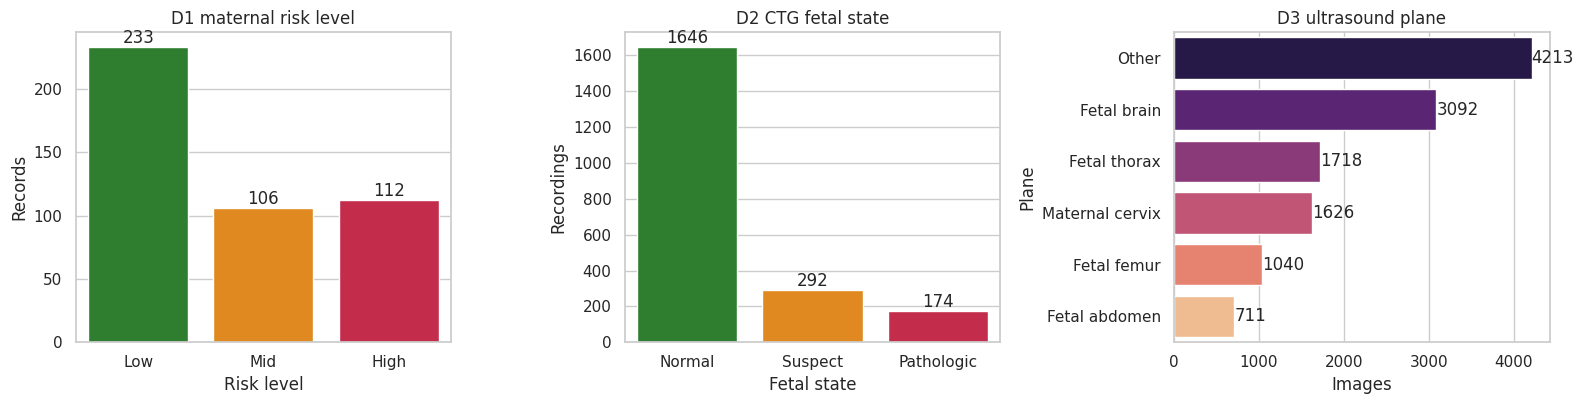

In [89]:
# [CELL 9] Class distributions of the three targets
risk_colours = ['forestgreen', 'darkorange', 'crimson']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sns.countplot(x=d1['y'].map(dict(enumerate(D1_CLASSES))), order=D1_CLASSES, palette=risk_colours, ax=axes[0])
axes[0].set_title('D1 maternal risk level'); axes[0].set_xlabel('Risk level'); axes[0].set_ylabel('Records')

sns.countplot(x=d2['y'].map(dict(enumerate(D2_CLASSES))), order=D2_CLASSES, palette=risk_colours, ax=axes[1])
axes[1].set_title('D2 CTG fetal state'); axes[1].set_xlabel('Fetal state'); axes[1].set_ylabel('Recordings')

sns.countplot(y=d3['Plane'], order=d3['Plane'].value_counts().index, palette='magma', ax=axes[2])
axes[2].set_title('D3 ultrasound plane'); axes[2].set_xlabel('Images'); axes[2].set_ylabel('Plane')

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
savefig('fig_class_distributions.png'); plt.show()

All three targets are imbalanced: maternal risk is only mildly skewed, but
CTG is dominated by "Normal" and the ultrasound planes by "Other" and brain
views, with abdomen the rarest. This confirms we report macro-F1 and use
class weighting rather than relying on accuracy.

### Step 3 — Feature distributions and relation to risk (D1)

Histograms (with KDE) show the shape and skew of each maternal vital.
The boxplots show how each vital differs across risk levels — the ones
that separate the classes most are the strongest predictors (direct test
of H1: is blood sugar the strongest signal?).

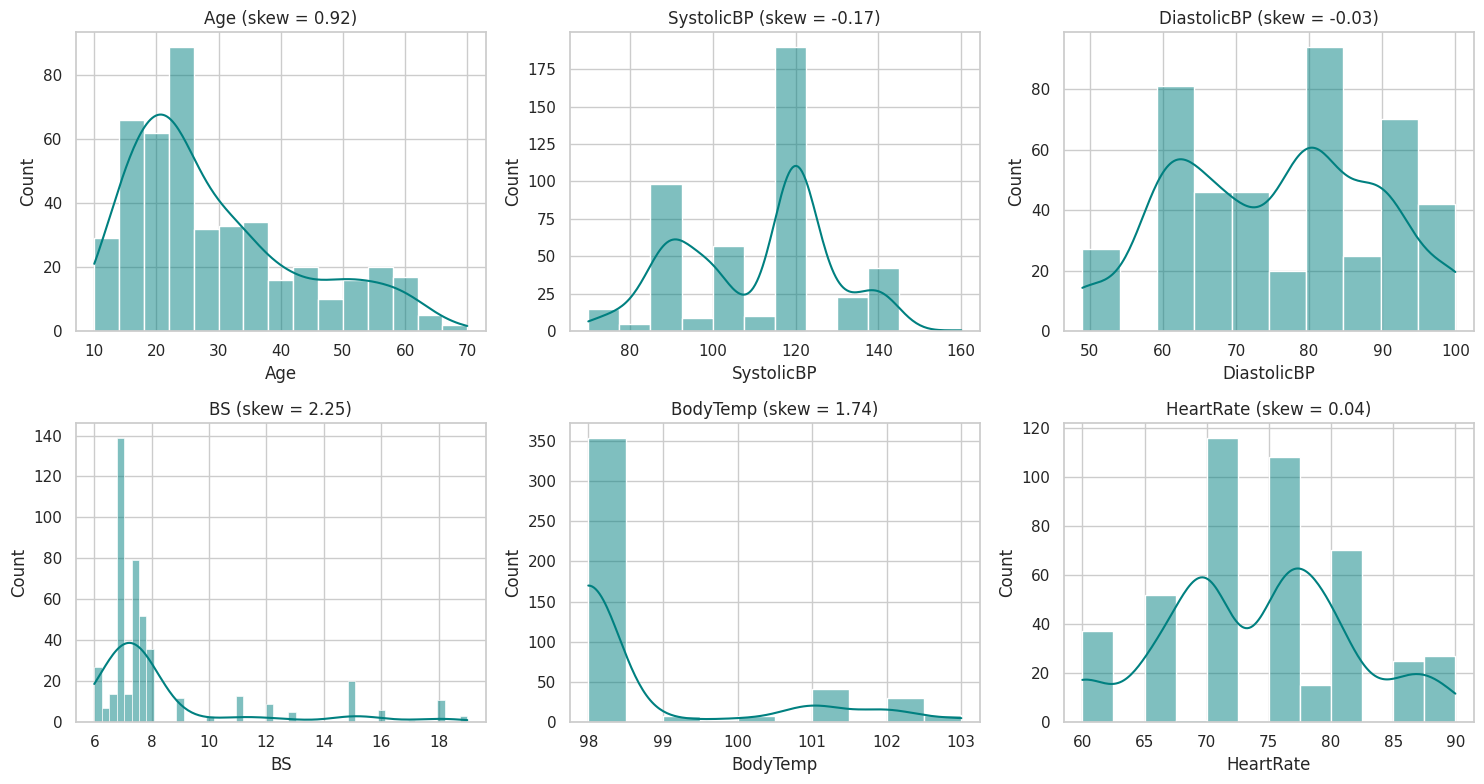

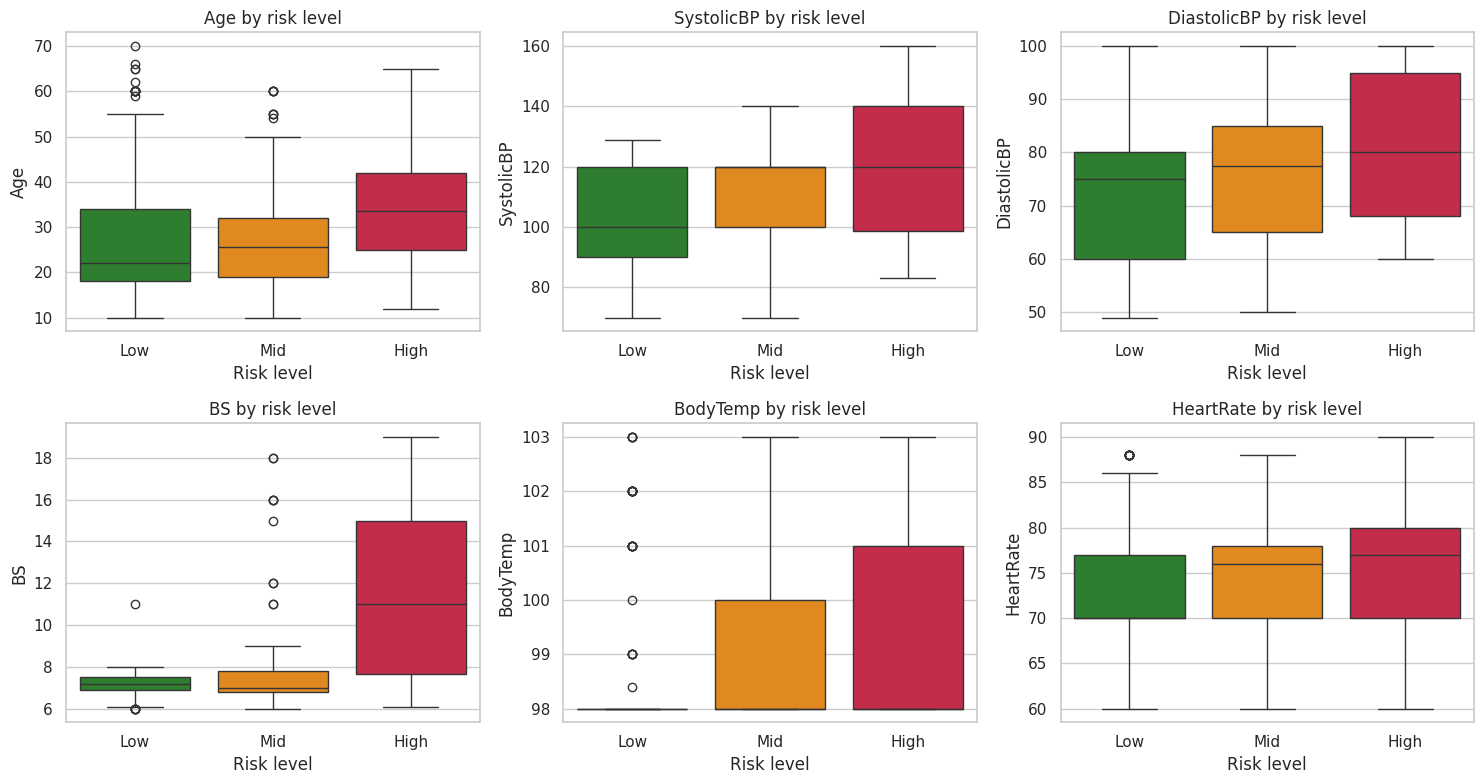

In [90]:
# [CELL 10] D1 feature distributions (histogram + density) and boxplots by risk level
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, D1_FEATS):
    sns.histplot(d1[col], kde=True, color='teal', ax=ax)
    ax.set_title(f'{col} (skew = {skew(d1[col]):.2f})'); ax.set_xlabel(col); ax.set_ylabel('Count')
savefig('fig_d1_distributions.png'); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, D1_FEATS):
    sns.boxplot(x=d1['y'].map(dict(enumerate(D1_CLASSES))), y=d1[col], order=D1_CLASSES, palette=risk_colours, ax=ax)
    ax.set_title(f'{col} by risk level'); ax.set_xlabel('Risk level'); ax.set_ylabel(col)
savefig('fig_d1_boxplots.png'); plt.show()

### Step 4 — Correlations and redundant features

Correlation matrices for both tabular datasets (features plus the numeric
class code `y`). Strong feature–feature correlations flag redundancy; strong
feature–`y` correlations hint at predictive power. The list below reports CTG
feature pairs with |r| > 0.9 as redundancy candidates.

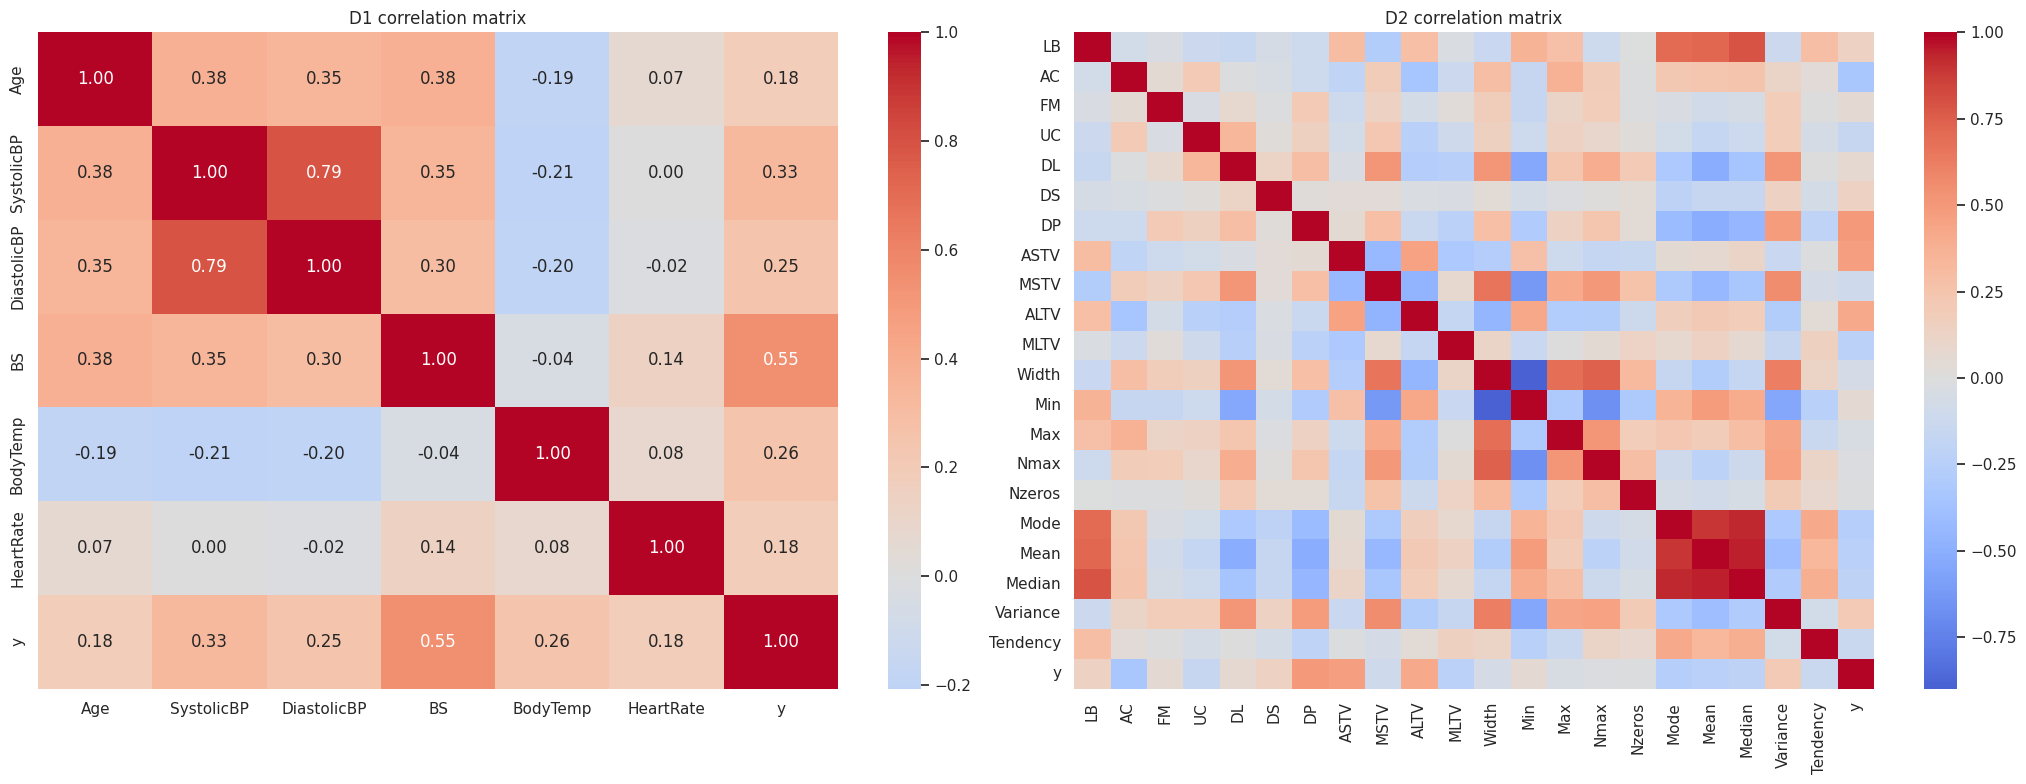

D2 feature pairs with |r| > 0.9:
Mean  Median    0.95
Mode  Median    0.93


In [91]:
# [CELL 11] Correlation matrices (y = numeric class code) and highly correlated CTG feature pairs
fig, axes = plt.subplots(1, 2, figsize=(21, 8))
sns.heatmap(d1[D1_FEATS + ['y']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('D1 correlation matrix')
sns.heatmap(d2[D2_FEATS + ['y']].corr(), cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('D2 correlation matrix')
savefig('fig_correlations.png'); plt.show()

corr = d2[D2_FEATS].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print('D2 feature pairs with |r| > 0.9:')
print(upper[upper > 0.9].sort_values(ascending=False).round(2).to_string())

### Step 5 — CTG feature separation by fetal state (D2)

Violin plots of six key CTG measurements across Normal, Suspect and
Pathologic recordings. Features where the three distributions sit apart are
the strongest signals for classifying fetal state.

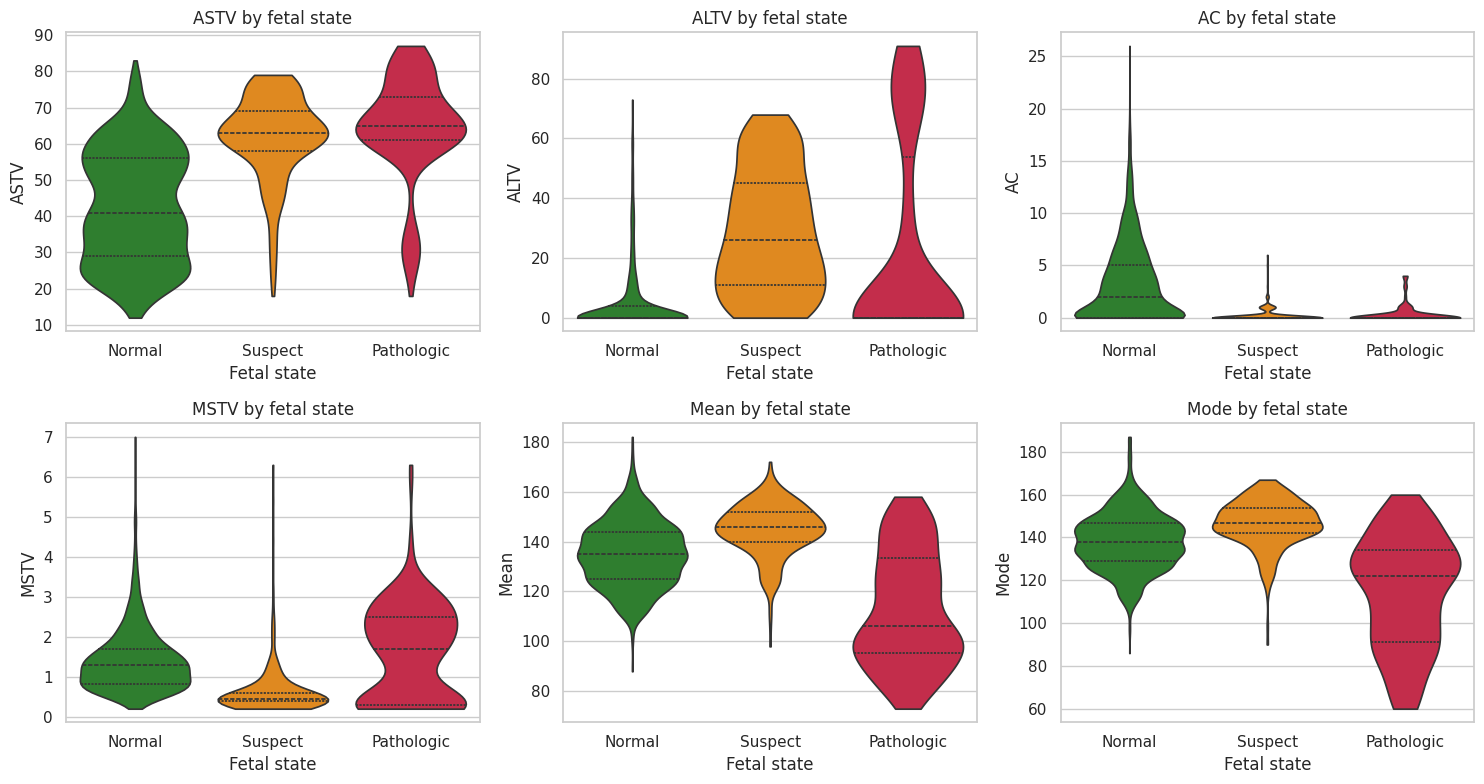

In [92]:
# [CELL 12] D2: how six CTG measurements differ between Normal, Suspect and Pathologic recordings
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ['ASTV', 'ALTV', 'AC', 'MSTV', 'Mean', 'Mode']):
    sns.violinplot(x=d2['y'].map(dict(enumerate(D2_CLASSES))), y=d2[col], order=D2_CLASSES,
                   palette=risk_colours, inner='quartile', cut=0, ax=ax)
    ax.set_title(f'{col} by fetal state'); ax.set_xlabel('Fetal state'); ax.set_ylabel(col)
savefig('fig_d2_violins.png'); plt.show()

### Step 6 — Ultrasound image samples (D3)

One example image per plane, to show what the CNN will classify. The planes
differ visually (brain, abdomen, femur, thorax, cervix, other), which is what
makes automatic recognition feasible.

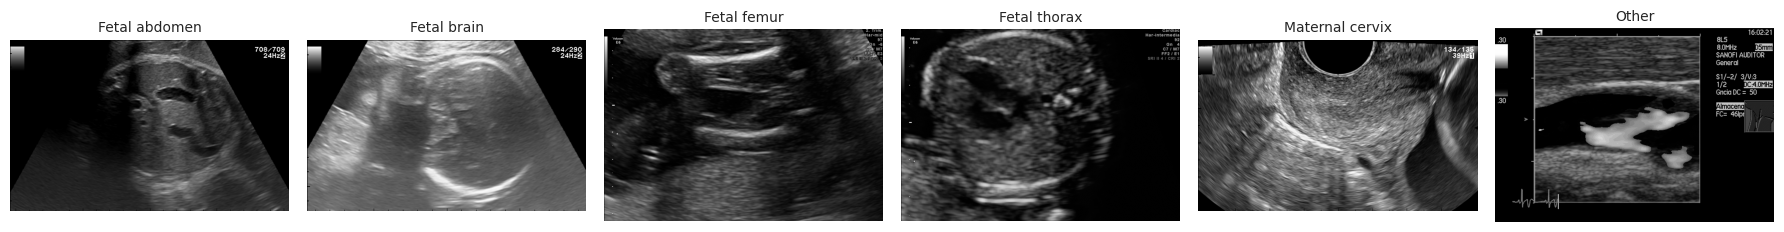

In [93]:
# Image EDA — one example per plane
IMG_DIR = '/content/drive/MyDrive/Images'

planes = sorted(d3['Plane'].unique())
fig, axes = plt.subplots(1, len(planes), figsize=(3 * len(planes), 3.4))
for ax, plane in zip(axes, planes):
    fname = d3[d3['Plane'] == plane].sample(1, random_state=SEED)['Image_name'].iloc[0]
    path = os.path.join(IMG_DIR, fname)
    if os.path.exists(path):
        ax.imshow(plt.imread(path), cmap='gray')
    ax.set_title(plane, fontsize=10); ax.axis('off')
savefig('fig_ultrasound_samples.png'); plt.show()

fetal femur and fetal thorax looks difficult to tell whereas fetal brain and detal abdomen looks similar.

### Step 7 — Feature relevance and selection

Rank each feature by three independent measures (ANOVA F-test, mutual
information, and Random Forest importance), scaled so the strongest feature
scores 1. Averaging the three gives a robust ranking. This directly tests H1
(is blood sugar the strongest maternal predictor) and tells us which CTG
features carry the signal.

D1 feature ranking
             ANOVA_F  MutualInfo  RF_importance  mean_rank
BS             1.000       1.000          1.000      1.000
SystolicBP     0.238       0.992          0.498      2.000
Age            0.075       0.504          0.431      3.667
DiastolicBP    0.146       0.302          0.319      4.000
HeartRate      0.072       0.394          0.290      5.000
BodyTemp       0.142       0.149          0.225      5.333

D2 top-10 feature ranking
          ANOVA_F  MutualInfo  RF_importance  mean_rank
ASTV        0.615       0.853          1.000      2.000
ALTV        0.612       0.879          0.831      2.667
Mean        0.554       0.791          0.722      4.000
MSTV        0.217       1.000          0.876      4.333
Mode        0.512       0.764          0.462      5.000
Median      0.463       0.686          0.412      6.333
DP          1.000       0.481          0.343      7.000
AC          0.304       0.671          0.411      7.333
Variance    0.279       0.702        

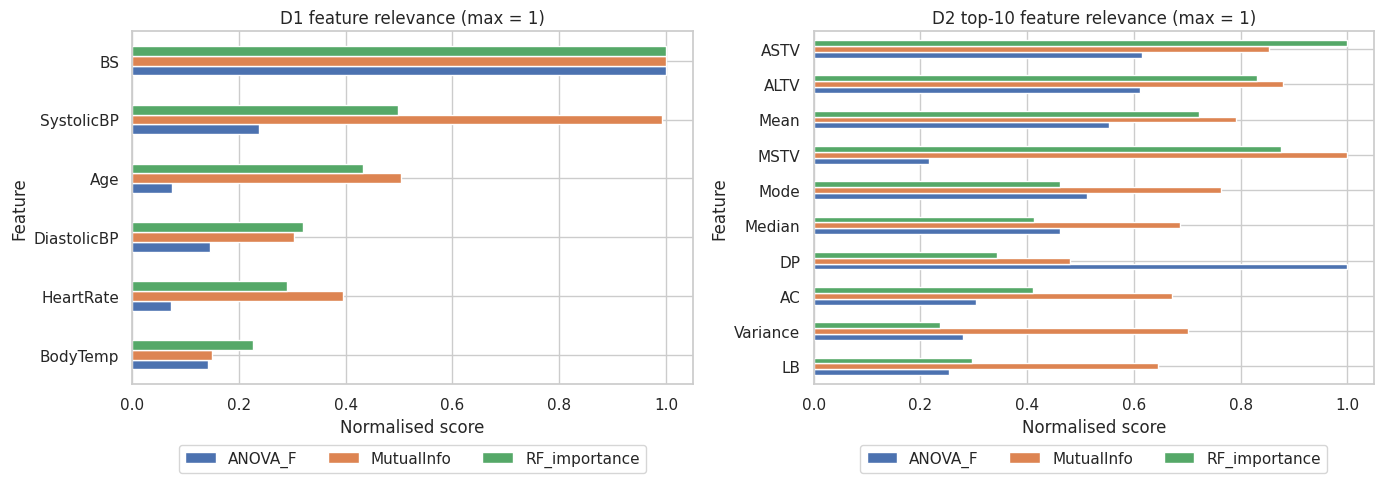

In [94]:
# [CELL 14] Feature relevance (exploration only; models use all features, so nothing leaks into the test set)
def rank_features(df, feats):
    X, y = df[feats].values, df['y'].values
    scores = pd.DataFrame(index=feats)
    scores['ANOVA_F'] = f_classif(X, y)[0]
    scores['MutualInfo'] = mutual_info_classif(X, y, random_state=SEED)
    scores['RF_importance'] = RandomForestClassifier(300, random_state=SEED).fit(X, y).feature_importances_
    scores = scores / scores.max()                                 # scale each score so the best feature = 1
    scores['mean_rank'] = scores.rank(ascending=False).mean(axis=1)
    return scores.sort_values('mean_rank')

d1_feature_rank = rank_features(d1, D1_FEATS)
d2_feature_rank = rank_features(d2, D2_FEATS)
print('D1 feature ranking'); print(d1_feature_rank.round(3).to_string())
print('\nD2 top-10 feature ranking'); print(d2_feature_rank.head(10).round(3).to_string())

score_cols = ['ANOVA_F', 'MutualInfo', 'RF_importance']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d1_feature_rank[score_cols].iloc[::-1].plot.barh(ax=axes[0], title='D1 feature relevance (max = 1)')
d2_feature_rank[score_cols].head(10).iloc[::-1].plot.barh(ax=axes[1], title='D2 top-10 feature relevance (max = 1)')
for ax in axes:
    ax.set_xlabel('Normalised score'); ax.set_ylabel('Feature')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
savefig('fig_feature_relevance.png'); plt.show()

## 3. Clustering (R2 / RQ4)

The data is already labelled, so clustering is not used to create labels. We
run it unsupervised, then compare the clusters it finds against the real
clinical classes. If they line up, the labels sit plainly in the features; if
not, the labels depend on subtler structure.

### Step 1 — Choosing the number of clusters
Elbow (inertia), silhouette, and GMM-BIC curves to pick a sensible k before
clustering.

In [95]:
# [CELL 15] Clustering step 1: choose k with the elbow, silhouette and GMM-BIC curves
def plot_k_selection(X_scaled, name):
    k_values = range(2, 9)
    inertia, silhouette, bic = [], [], []
    for k in k_values:
        km = KMeans(k, n_init=10, random_state=SEED).fit(X_scaled)
        inertia.append(km.inertia_)
        silhouette.append(silhouette_score(X_scaled, km.labels_))
        bic.append(GaussianMixture(k, reg_covar=1e-3, n_init=3, random_state=SEED).fit(X_scaled).bic(X_scaled))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, values, title, label in zip(axes, [inertia, silhouette, bic],
                                        ['K-Means elbow', 'Silhouette score', 'GMM BIC'],
                                        ['Inertia', 'Silhouette', 'BIC']):
        ax.plot(list(k_values), values, 'o-'); ax.set_title(f'{name} {title}'); ax.set_xlabel('Number of clusters k'); ax.set_ylabel(label)
    savefig(f'fig_{name}_k_selection.png'); plt.show()

### Step 2 — Compare clustering algorithms and score against the labels

Run K-Means, GMM (EM), Agglomerative and DBSCAN. We report internal quality
(silhouette, Davies-Bouldin) and, crucially, agreement with the true clinical
labels (ARI and NMI). ARI/NMI are what actually answer RQ4 — silhouette alone
only measures tidiness, not whether the clusters match the clinical classes.

In [96]:
# [CELL 16] Clustering step 2: compare K-Means, GMM (EM), Agglomerative and DBSCAN
def compare_clusterers(X_scaled, y_true, n_clusters=3):
    # DBSCAN radius: 90th percentile of the distance to the 5th nearest neighbour
    knn_dist = np.sort(NearestNeighbors(n_neighbors=5).fit(X_scaled).kneighbors(X_scaled)[0][:, -1])
    eps = float(np.percentile(knn_dist, 90))
    algorithms = {'K-Means': KMeans(n_clusters, n_init=15, random_state=SEED),
                  'GMM (EM)': GaussianMixture(n_clusters, reg_covar=1e-3, n_init=3, random_state=SEED),
                  'Agglomerative (Ward)': AgglomerativeClustering(n_clusters),
                  f'DBSCAN (eps={eps:.2f})': DBSCAN(eps=eps, min_samples=5)}
    rows, labels = [], {}
    for name, algorithm in algorithms.items():
        found = algorithm.fit_predict(X_scaled)
        labels[name] = found
        not_noise = found != -1                                    # DBSCAN marks noise points as -1
        enough_clusters = len(set(found[not_noise])) > 1
        rows.append({'Algorithm': name,
                     'Clusters': len(set(found[not_noise])),
                     'Noise points': int((~not_noise).sum()),
                     'Silhouette': silhouette_score(X_scaled[not_noise], found[not_noise]) if enough_clusters else np.nan,
                     'Davies-Bouldin': davies_bouldin_score(X_scaled[not_noise], found[not_noise]) if enough_clusters else np.nan,
                     'ARI vs labels': adjusted_rand_score(y_true, found),
                     'NMI vs labels': normalized_mutual_info_score(y_true, found)})
    return pd.DataFrame(rows).round(3), labels

def plot_clusters_pca(X_scaled, y_true, labels, class_names, name):
    # 2-D PCA view used only for display; each panel has a legend
    pca = PCA(2, random_state=SEED).fit(X_scaled)
    points = pca.transform(X_scaled)
    panels = [('K-Means clusters', labels['K-Means']), ('GMM clusters', labels['GMM (EM)']), ('True clinical label', y_true)]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
    for ax, (title, values) in zip(axes, panels):
        for value in np.unique(values):
            mask = values == value
            if title == 'True clinical label':
                colour, text = risk_colours[value], class_names[value]
            else:
                colour, text = plt.cm.tab10(value), f'Cluster {value}'
            ax.scatter(points[mask, 0], points[mask, 1], s=14, alpha=0.7, color=colour, label=text)
        ax.set_title(f'{name}: {title} (PCA view)'); ax.legend(fontsize=9)
        ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)')
        ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)')
    savefig(f'fig_{name}_clusters_pca.png'); plt.show()

### Step 3 — Run clustering on both tabular datasets

Features are scaled first. Labels are used only afterwards, to score how well
the unsupervised clusters match the clinical classes (ARI/NMI) and in the
crosstab. Low-to-moderate agreement would support H4: risk is a gradient, so
natural clusters only partly line up with the discrete clinical labels.

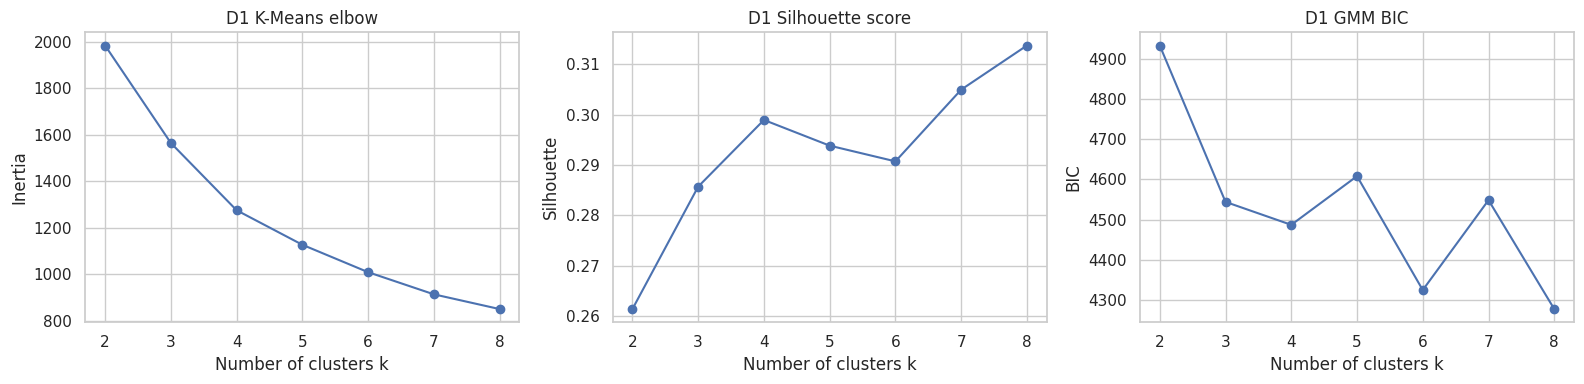


D1 clustering results
           Algorithm  Clusters  Noise points  Silhouette  Davies-Bouldin  ARI vs labels  NMI vs labels
             K-Means         3             0       0.286           1.343          0.104          0.130
            GMM (EM)         3             0       0.233           1.613          0.285          0.210
Agglomerative (Ward)         3             0       0.252           1.451          0.100          0.135
   DBSCAN (eps=1.48)         3            24       0.316           1.009          0.148          0.147


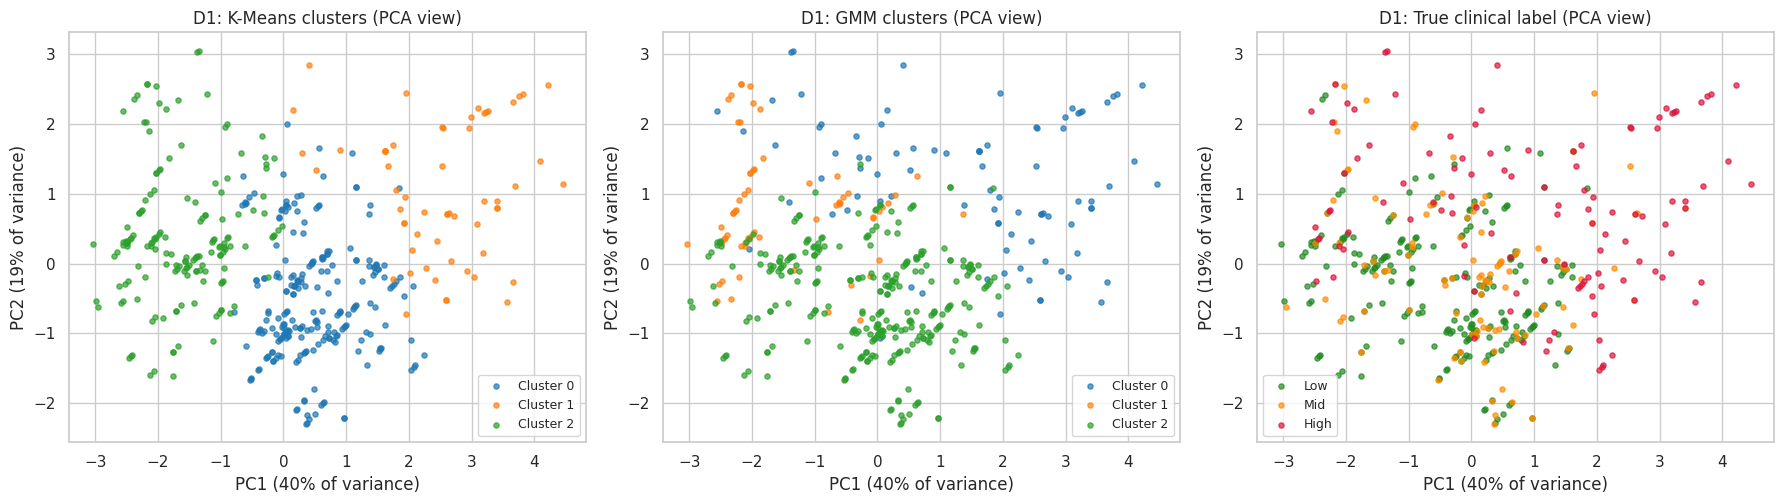

D1 K-Means clusters against clinical classes:
y        Low  Mid  High
cluster                
0        135   63    34
1          1   10    47
2         97   33    31


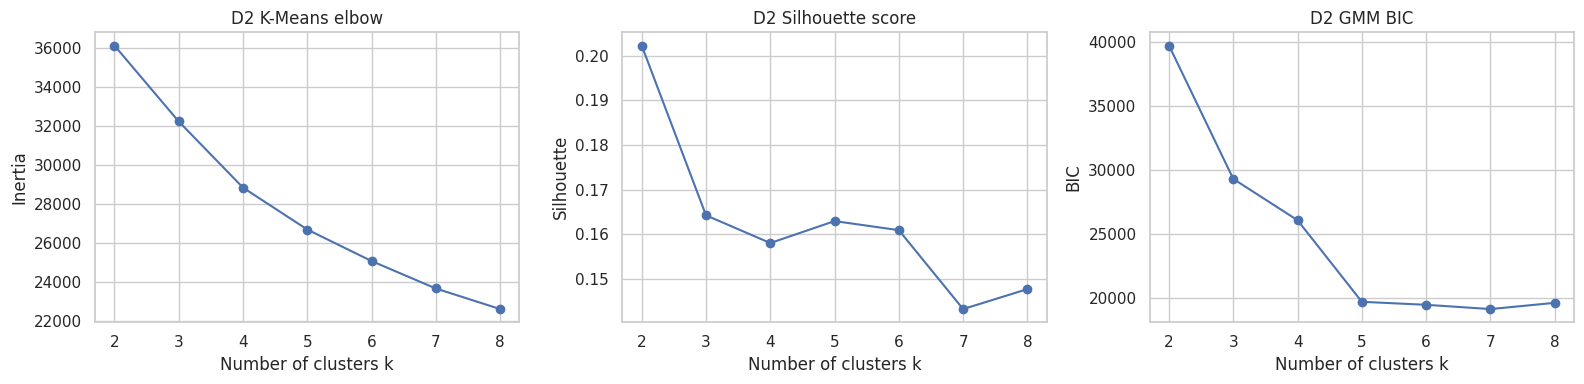


D2 clustering results
           Algorithm  Clusters  Noise points  Silhouette  Davies-Bouldin  ARI vs labels  NMI vs labels
             K-Means         3             0       0.164           1.878          0.188          0.196
            GMM (EM)         3             0       0.126           2.529          0.062          0.129
Agglomerative (Ward)         3             0       0.092           2.089          0.204          0.158
   DBSCAN (eps=2.97)        12           111       0.096           0.889          0.203          0.169


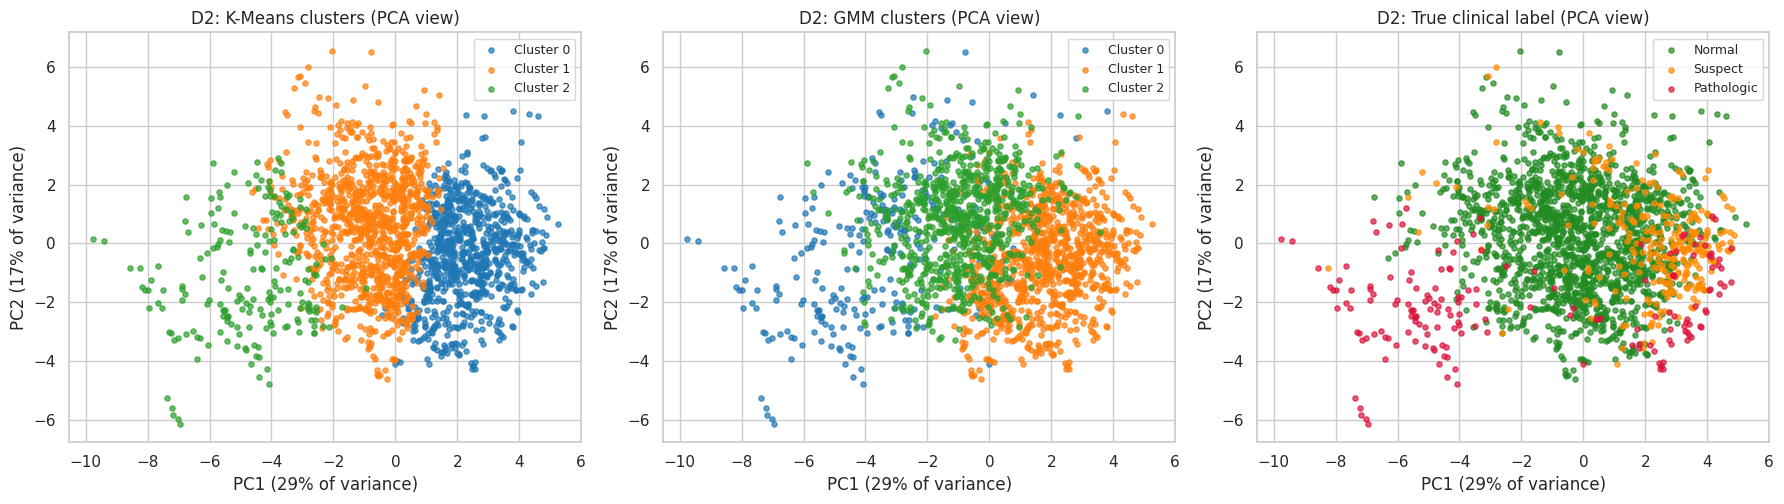

D2 K-Means clusters against clinical classes:
y        Normal  Suspect  Pathologic
cluster                             
0           530      240          64
1          1023       41           5
2            93       11         105


In [97]:
# [CELL 17] Run the clustering study on D1 and D2 (features scaled first; labels are used only for evaluation)
CLUSTER_RESULTS = {}
for name, df, feats, class_names in [('D1', d1, D1_FEATS, D1_CLASSES), ('D2', d2, D2_FEATS, D2_CLASSES)]:
    X_scaled = StandardScaler().fit_transform(df[feats])
    plot_k_selection(X_scaled, name)
    table, labels = compare_clusterers(X_scaled, df['y'].values)
    CLUSTER_RESULTS[name] = table
    print(f'\n{name} clustering results'); print(table.to_string(index=False))
    plot_clusters_pca(X_scaled, df['y'].values, labels, class_names, name)
    print(f'{name} K-Means clusters against clinical classes:')
    print(pd.crosstab(labels['K-Means'], df['y'].map(dict(enumerate(class_names))), rownames=['cluster'])[class_names].to_string())

**RQ4 result.** ARI and NMI are low on both datasets (D1 best ~0.29, D2 best
~0.20), so the unsupervised clusters only partly match the clinical labels —
confirming H4. The crosstabs show why: clustering recovers the extremes (a
near-pure high-risk group in D1, a clean Normal and a Pathologic-leaning group
in D2) but the middle classes (Mid, Suspect) never form their own cluster and
scatter across groups. This is expected if risk is a gradient rather than three
discrete states, and it justifies moving to supervised models that can learn the
human-defined class boundaries. GMM (EM) also satisfies the generative-method
requirement.

## 4. Baseline Classical Models (R3)

### Setup — split and evaluation protocol
Stratified 80/20 train/test split, with stratified 5-fold cross-validation on
the training set. The test set is used only for final scores. We report macro-F1,
precision and recall (chosen for class imbalance), plus recall on the critical
class (High risk / Pathologic), since missing those cases is the costly error.

In [98]:
# [CELL 18] Stratified 80/20 train/test split for D1 and D2 (test set is used only for the final scores)
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
CRITICAL_CLASS = 2                      # High risk (D1) and Pathologic (D2)

SPLITS = {}
for name, df, feats, class_names in [('D1', d1, D1_FEATS, D1_CLASSES), ('D2', d2, D2_FEATS, D2_CLASSES)]:
    X_train, X_test, y_train, y_test = train_test_split(df[feats], df['y'], test_size=0.2, stratify=df['y'], random_state=SEED)
    SPLITS[name] = {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test,
                    'feats': feats, 'classes': class_names}
    print(f'{name}: train {X_train.shape}, test {X_test.shape}, train class counts {y_train.value_counts().sort_index().to_dict()}')

RESULTS = []       # one row of scores per (dataset, model)
PREDS = {}         # (dataset, model) -> (true labels, predicted labels, probabilities); every metric uses these

def record(dataset, model, y_true, y_pred, proba=None, cv_f1=np.nan, cv_sd=np.nan, family=''):
    # store the test-set scores and the raw predictions of one model; an older entry of the same model is replaced (safe to re-run)
    RESULTS[:] = [r for r in RESULTS if not (r['Dataset'] == dataset and r['Model'] == model)]
    row = {'Dataset': dataset, 'Family': family, 'Model': model, 'CV macro-F1': cv_f1, 'CV sd': cv_sd,
           'Test acc': accuracy_score(y_true, y_pred),
           'Test macro-F1': f1_score(y_true, y_pred, average='macro'),
           'Test macro-P': precision_score(y_true, y_pred, average='macro'),
           'Test macro-R': recall_score(y_true, y_pred, average='macro'),
           'Critical-class recall': recall_score(y_true, y_pred, labels=[CRITICAL_CLASS], average=None)[0]}
    row['Test AUC (OvR)'] = roc_auc_score(y_true, proba, multi_class='ovr', average='macro') if proba is not None else np.nan
    RESULTS.append(row)
    PREDS[(dataset, model)] = (np.asarray(y_true), np.asarray(y_pred), None if proba is None else np.asarray(proba))

D1: train (360, 6), test (91, 6), train class counts {0: 186, 1: 85, 2: 89}
D2: train (1689, 21), test (423, 21), train class counts {0: 1316, 1: 234, 2: 139}


### Baseline models

Nine models across families (tree, distance, generative, linear, kernel,
ensemble), each in a pipeline that scales inside cross-validation so no test
data leaks. Evaluated with 5-fold CV macro-F1 on the training set, then a single
held-out test evaluation. We watch critical-class recall closely given the
class imbalance.

In [99]:
# [CELL 19] Baseline models: scaling is inside each pipeline, so it is fitted on training folds only
def baseline_models():
    return {
        'Decision Tree':        ('Classical',  make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=SEED))),
        'k-Nearest Neighbours': ('Classical',  make_pipeline(StandardScaler(), KNeighborsClassifier(5))),
        'Gaussian Naive Bayes': ('Generative', make_pipeline(StandardScaler(), GaussianNB())),
        'Logistic Regression':  ('Linear',     make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED))),
        'Perceptron':           ('Linear',     make_pipeline(StandardScaler(), Perceptron(random_state=SEED))),
        'SVM (RBF)':            ('Kernel',     make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED))),
        'Random Forest':        ('Ensemble',   make_pipeline(StandardScaler(), RandomForestClassifier(200, random_state=SEED))),
        'Extra Trees':          ('Ensemble',   make_pipeline(StandardScaler(), ExtraTreesClassifier(200, random_state=SEED))),
        'Gradient Boosting':    ('Ensemble',   make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=SEED)))}

def fit_and_record(dataset, model_name, family, pipeline):
    # 5-fold CV on the training data, then one fit on all training data and one test evaluation
    S = SPLITS[dataset]
    cv_scores = cross_validate(pipeline, S['X_train'], S['y_train'], cv=CV, scoring='f1_macro', n_jobs=-1)['test_score']
    pipeline.fit(S['X_train'], S['y_train'])
    proba = pipeline.predict_proba(S['X_test']) if hasattr(pipeline, 'predict_proba') else None
    record(dataset, model_name, S['y_test'], pipeline.predict(S['X_test']), proba, cv_scores.mean(), cv_scores.std(), family)

FITTED = {'D1': {}, 'D2': {}}
for dataset in ['D1', 'D2']:
    for model_name, (family, pipeline) in baseline_models().items():
        fit_and_record(dataset, model_name, family, pipeline)
        FITTED[dataset][model_name] = pipeline

TABLE_COLUMNS = ['Model', 'Family', 'CV macro-F1', 'CV sd', 'Test acc', 'Test macro-F1', 'Critical-class recall', 'Test AUC (OvR)']
results_df = pd.DataFrame(RESULTS)
for dataset in ['D1', 'D2']:
    table = results_df[results_df['Dataset'] == dataset][TABLE_COLUMNS].sort_values('CV macro-F1', ascending=False)
    print(f'\n{dataset} baseline models (sorted by CV macro-F1)'); print(table.round(3).to_string(index=False))


D1 baseline models (sorted by CV macro-F1)
               Model     Family  CV macro-F1  CV sd  Test acc  Test macro-F1  Critical-class recall  Test AUC (OvR)
       Random Forest   Ensemble        0.614  0.051     0.648          0.557                  0.739           0.788
   Gradient Boosting   Ensemble        0.609  0.040     0.637          0.550                  0.696           0.789
           SVM (RBF)     Kernel        0.583  0.026     0.670          0.516                  0.783           0.793
         Extra Trees   Ensemble        0.568  0.020     0.659          0.568                  0.783           0.714
k-Nearest Neighbours  Classical        0.562  0.056     0.648          0.562                  0.652           0.750
       Decision Tree  Classical        0.551  0.013     0.626          0.599                  0.696           0.723
          Perceptron     Linear        0.542  0.059     0.396          0.420                  0.565             NaN
Gaussian Naive Bayes Generat

**R3 result.** Tree ensembles (Random Forest, Gradient Boosting) top both
datasets, while linear models (Logistic Regression, Perceptron) trail —
confirming H2/RQ2 that non-linear models win because risk depends on feature
interactions. Performance mirrors the clustering: D1 is hard (best test
macro-F1 ~ 0.57), matching its low cluster–label agreement, while D2 is well
separated (~0.91). Critical-class recall is already strong for the ensembles
(D2 Pathologic ~0.89, D1 High-risk ~0.78), so explicit class weighting was not
required. Naïve Bayes is weakest, consistent with the correlated features found
in EDA violating its independence assumption.

### Hyperparameter tuning — validation curves

Training vs cross-validation macro-F1 as a key hyperparameter varies, for kNN
(k), Decision Tree (max depth) and Naïve Bayes (smoothing). The gap between the
two lines shows overfitting: the Decision Tree in particular overfits at high
depth, which is why a shallow tree generalises better. Best values are selected
by cross-validation.

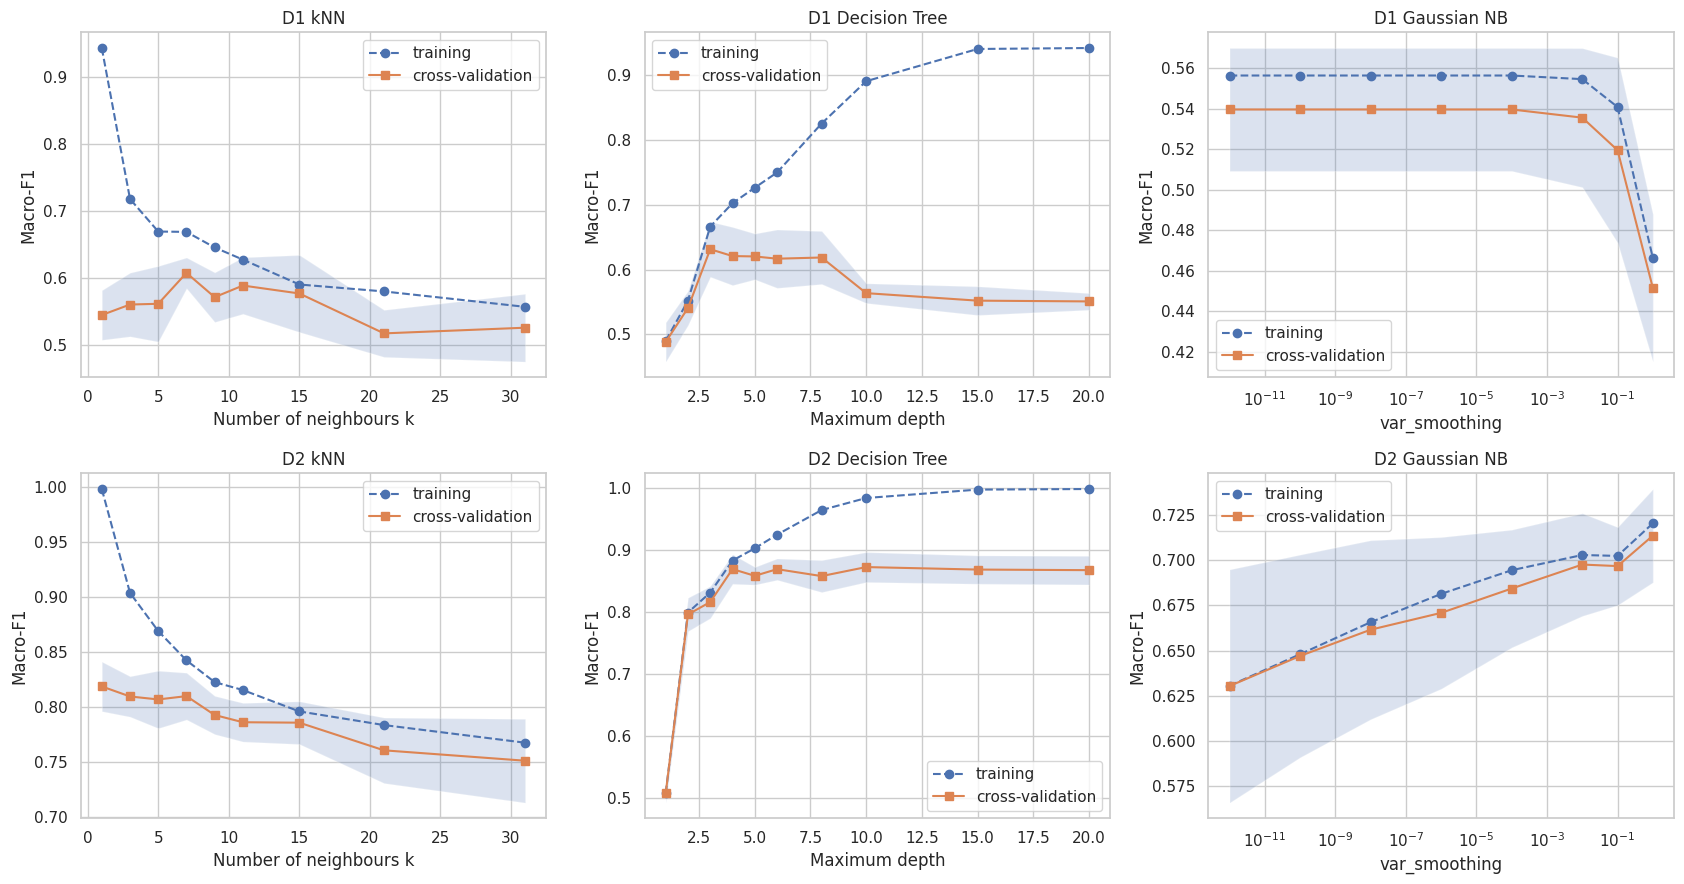

Best values found by cross-validation: {'D1': {'k': 7, 'depth': 3, 'smoothing': 1e-12}, 'D2': {'k': 1, 'depth': 10, 'smoothing': 1}}


In [100]:
# [CELL 20] Hyper-parameter experiments: training vs cross-validation score as one parameter changes
def plot_validation_curve(ax, pipeline, S, parameter, values, title, xlabel):
    train_scores, cv_scores = validation_curve(pipeline, S['X_train'], S['y_train'], param_name=parameter,
                                               param_range=values, cv=CV, scoring='f1_macro', n_jobs=-1)
    ax.plot(values, train_scores.mean(axis=1), 'o--', label='training')
    ax.plot(values, cv_scores.mean(axis=1), 's-', label='cross-validation')
    ax.fill_between(values, cv_scores.mean(axis=1) - cv_scores.std(axis=1), cv_scores.mean(axis=1) + cv_scores.std(axis=1), alpha=0.2)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('Macro-F1'); ax.legend()
    return values[int(cv_scores.mean(axis=1).argmax())]            # value with the best CV score

BEST_PARAMS = {}
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for row, dataset in enumerate(['D1', 'D2']):
    S = SPLITS[dataset]
    best_k = plot_validation_curve(axes[row, 0], make_pipeline(StandardScaler(), KNeighborsClassifier()), S,
                                   'kneighborsclassifier__n_neighbors', [1, 3, 5, 7, 9, 11, 15, 21, 31], f'{dataset} kNN', 'Number of neighbours k')
    best_depth = plot_validation_curve(axes[row, 1], make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=SEED)), S,
                                       'decisiontreeclassifier__max_depth', [1, 2, 3, 4, 5, 6, 8, 10, 15, 20], f'{dataset} Decision Tree', 'Maximum depth')
    best_smoothing = plot_validation_curve(axes[row, 2], make_pipeline(StandardScaler(), GaussianNB()), S,
                                           'gaussiannb__var_smoothing', [1e-12, 1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1e-1, 1], f'{dataset} Gaussian NB', 'var_smoothing')
    axes[row, 2].set_xscale('log')
    BEST_PARAMS[dataset] = {'k': best_k, 'depth': best_depth, 'smoothing': best_smoothing}
savefig('fig_validation_curves.png'); plt.show()
print('Best values found by cross-validation:', BEST_PARAMS)

**Tuning.** Best cross-validated settings: D1 favours a shallow tree (depth 3)
and more kNN neighbours (k=7), because its overlapping risk levels are noisy; D2
supports a deeper tree (depth 10) and k=1, reflecting cleaner class separation.
This reinforces the recurring finding that D1 is intrinsically harder than D2.

### Grid search on the winning ensembles

Full grid search (5-fold CV, macro-F1) over Random Forest and Gradient Boosting
— the two strongest baselines. Tuned versions are added to the results table for
comparison against their default settings.

In [101]:
# [CELL 21] Grid search for the two ensembles (5-fold CV, scoring = macro-F1)
# The scaler is part of each pipeline, exactly as in the baseline models, so every fold is scaled on its own training part
PARAM_GRIDS = {
    'Random Forest': (
        make_pipeline(StandardScaler(), RandomForestClassifier(random_state=SEED)),
        {'randomforestclassifier__n_estimators': [100, 300],
         'randomforestclassifier__max_depth': [5, 10, None],
         'randomforestclassifier__min_samples_split': [2, 5],
         'randomforestclassifier__criterion': ['gini', 'entropy']}),
    'Gradient Boosting': (
        make_pipeline(StandardScaler(), GradientBoostingClassifier(random_state=SEED)),
        {'gradientboostingclassifier__n_estimators': [100, 200],
         'gradientboostingclassifier__learning_rate': [0.05, 0.1],
         'gradientboostingclassifier__max_depth': [2, 3]})}

TUNED = {'D1': {}, 'D2': {}}
for dataset in ['D1', 'D2']:
    S = SPLITS[dataset]
    for model_name, (pipeline, grid) in PARAM_GRIDS.items():
        search = GridSearchCV(pipeline, grid, scoring='f1_macro', cv=CV, n_jobs=-1).fit(S['X_train'], S['y_train'])
        TUNED[dataset][model_name] = search.best_estimator_
        best_sd = search.cv_results_['std_test_score'][search.best_index_]
        record(dataset, f'{model_name} (tuned)', S['y_test'], search.predict(S['X_test']), search.predict_proba(S['X_test']),
               search.best_score_, best_sd, 'Ensemble')
        print(f'{dataset} {model_name}: best parameters {search.best_params_}, CV macro-F1 = {search.best_score_:.3f}')

D1 Random Forest: best parameters {'randomforestclassifier__criterion': 'gini', 'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__n_estimators': 300}, CV macro-F1 = 0.657
D1 Gradient Boosting: best parameters {'gradientboostingclassifier__learning_rate': 0.05, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__n_estimators': 100}, CV macro-F1 = 0.657
D2 Random Forest: best parameters {'randomforestclassifier__criterion': 'entropy', 'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__n_estimators': 100}, CV macro-F1 = 0.887
D2 Gradient Boosting: best parameters {'gradientboostingclassifier__learning_rate': 0.05, 'gradientboostingclassifier__max_depth': 2, 'gradientboostingclassifier__n_estimators': 200}, CV macro-F1 = 0.899


**Tuned ensembles.** Grid search lifted D1 modestly (RF and GB both to CV
macro-F1 ≈ 0.66, up from ≈ 0.61) but barely changed D2 (GB ≈ 0.90), which was
already near its ceiling. Both datasets preferred shallow, slow Gradient Boosting
(depth 2, lr 0.05), consistent with the overfitting seen in the validation
curves. Default ensembles were already strong, so tuning gave a small gain
rather than a step change.

In [102]:
# [CELL 22] Single models re-fitted with the best parameter from the validation curves
for dataset in ['D1', 'D2']:
    best = BEST_PARAMS[dataset]
    tuned_models = [
        (f'kNN (k={best["k"]})', 'Classical', make_pipeline(StandardScaler(), KNeighborsClassifier(best['k']))),
        (f'Decision Tree (depth={best["depth"]})', 'Classical', make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=best['depth'], random_state=SEED))),
        (f'Gaussian NB (var_smoothing={best["smoothing"]:g})', 'Generative', make_pipeline(StandardScaler(), GaussianNB(var_smoothing=best['smoothing'])))]
    for model_name, family, pipeline in tuned_models:
        fit_and_record(dataset, model_name, family, pipeline)
        FITTED[dataset][model_name] = pipeline

### Decision tree interpretability

A depth-3 tree for each dataset, shown as a diagram and as text rules. Unlike the
ensembles, a single shallow tree is fully readable, so we can check the model's
logic is clinically sensible. The root split shows the most decisive feature,
which should match the feature-importance ranking.

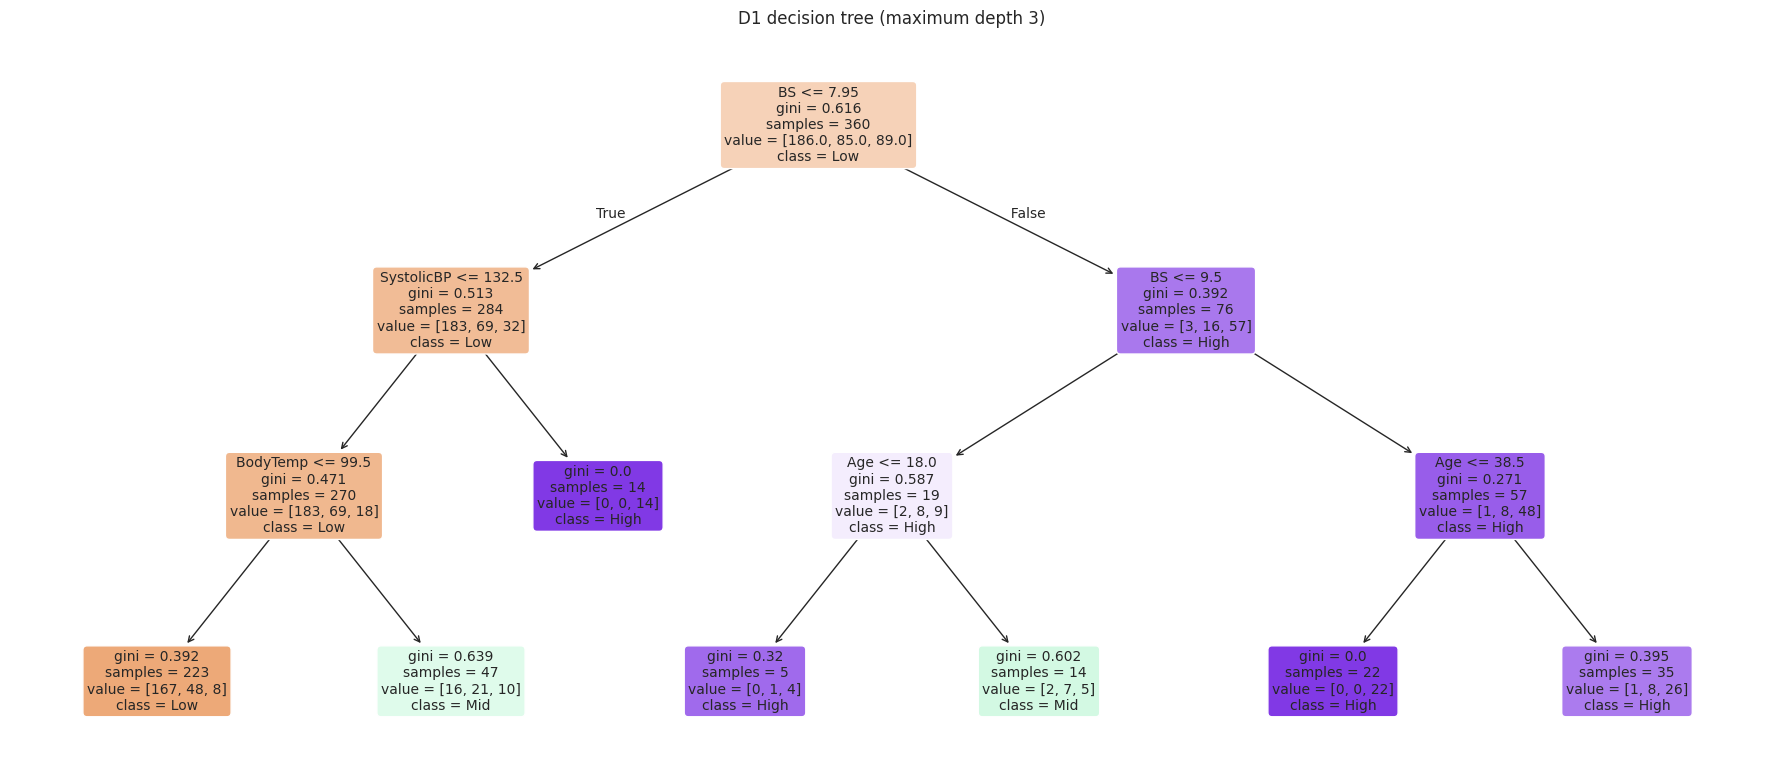


D1 tree rules:
|--- BS <= 7.95
|   |--- SystolicBP <= 132.50
|   |   |--- BodyTemp <= 99.50
|   |   |   |--- class: 0
|   |   |--- BodyTemp >  99.50
|   |   |   |--- class: 1
|   |--- SystolicBP >  132.50
|   |   |--- class: 2
|--- BS >  7.95
|   |--- BS <= 9.50
|   |   |--- Age <= 18.00
|   |   |   |--- class: 2
|   |   |--- Age >  18.00
|   |   |   |--- class: 1
|   |--- BS >  9.50
|   |   |--- Age <= 38.50
|   |   |   |--- class: 2
|   |   |--- Age >  38.50
|   |   |   |--- class: 2

D1 depth-3 tree test macro-F1: 0.544


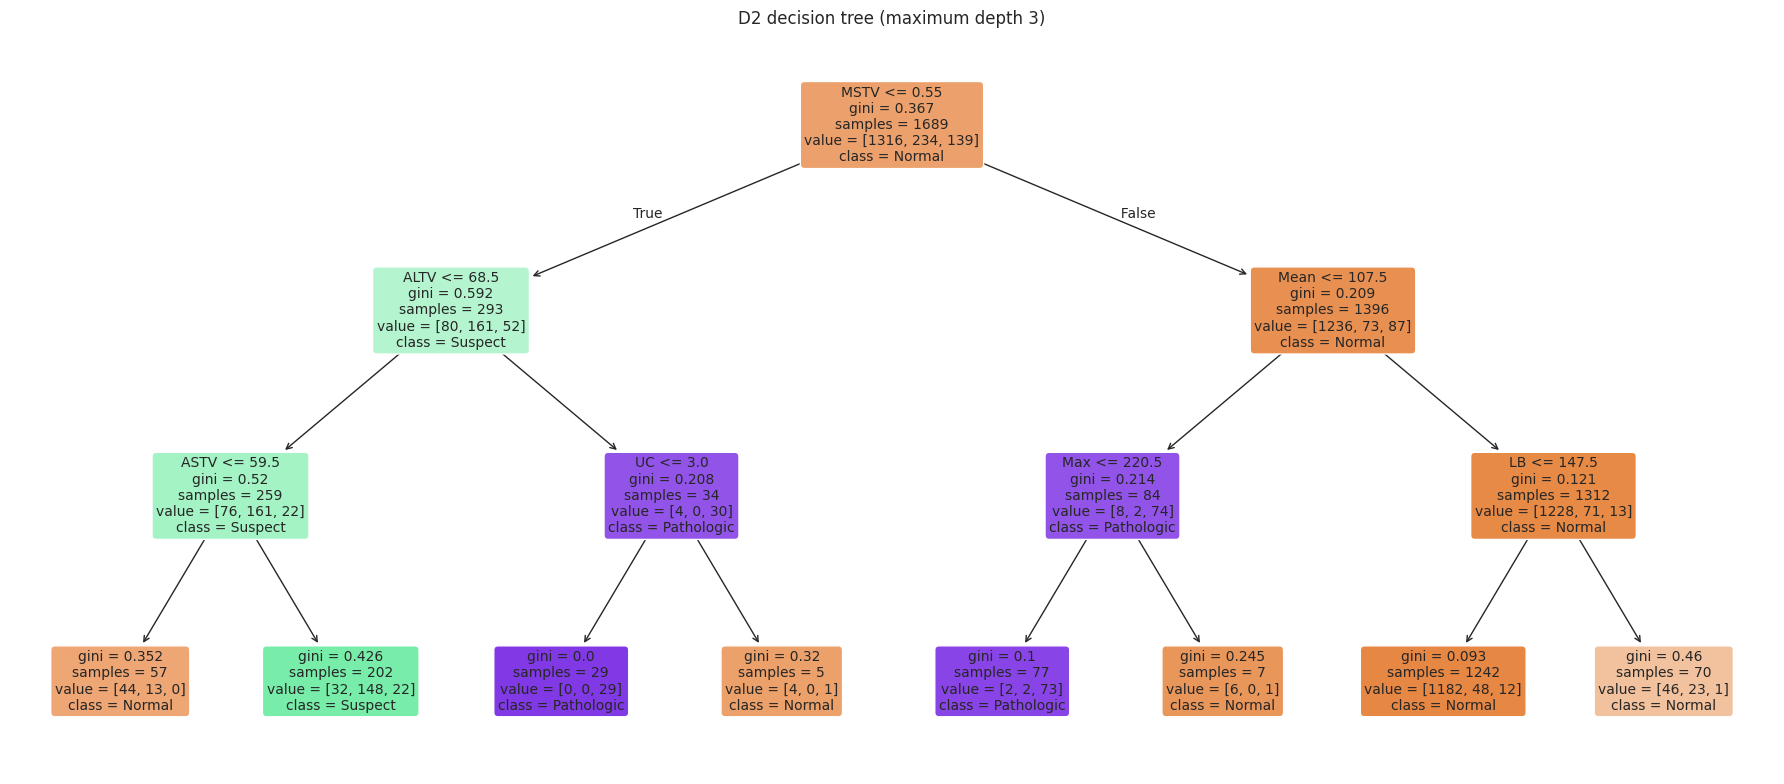


D2 tree rules:
|--- MSTV <= 0.55
|   |--- ALTV <= 68.50
|   |   |--- ASTV <= 59.50
|   |   |   |--- class: 0
|   |   |--- ASTV >  59.50
|   |   |   |--- class: 1
|   |--- ALTV >  68.50
|   |   |--- UC <= 3.00
|   |   |   |--- class: 2
|   |   |--- UC >  3.00
|   |   |   |--- class: 0
|--- MSTV >  0.55
|   |--- Mean <= 107.50
|   |   |--- Max <= 220.50
|   |   |   |--- class: 2
|   |   |--- Max >  220.50
|   |   |   |--- class: 0
|   |--- Mean >  107.50
|   |   |--- LB <= 147.50
|   |   |   |--- class: 0
|   |   |--- LB >  147.50
|   |   |   |--- class: 0

D2 depth-3 tree test macro-F1: 0.829


In [103]:
# [CELL 23] Decision trees limited to depth 3: readable rules for each dataset (one large figure each)
for dataset in ['D1', 'D2']:
    S = SPLITS[dataset]
    tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(S['X_train'], S['y_train'])
    plt.figure(figsize=(18, 8))
    plot_tree(tree, feature_names=S['feats'], class_names=S['classes'], filled=True, rounded=True, fontsize=10)
    plt.title(f'{dataset} decision tree (maximum depth 3)')
    savefig(f'fig_{dataset}_decision_tree.png'); plt.show()
    print(f'\n{dataset} tree rules:'); print(export_text(tree, feature_names=S['feats']))
    print(f'{dataset} depth-3 tree test macro-F1: {f1_score(S["y_test"], tree.predict(S["X_test"]), average="macro"):.3f}')

**Decision tree rules.** The D1 tree splits first on blood sugar (BS ≤ 7.95)
then systolic BP, directly confirming H1 — blood sugar is the single most
decisive predictor, blood pressure second. Its rules are clinically sensible
(high glucose or high BP → high risk). The D2 tree splits on heart-rate
variability (MSTV, ALTV, ASTV), the established markers of fetal distress,
matching the EDA. These readable trees score below the ensembles (D1 0.54,
D2 0.83 vs ~0.57 and ~0.91), illustrating the interpretability–accuracy
trade-off.

### Confusion matrices

For the best models per dataset, showing which classes are confused. We expect
the middle class (Mid risk / Suspect) to be hardest, consistent with the
clustering result and the gradient hypothesis (H4). The critical class (High /
Pathologic) is the one we most want caught.

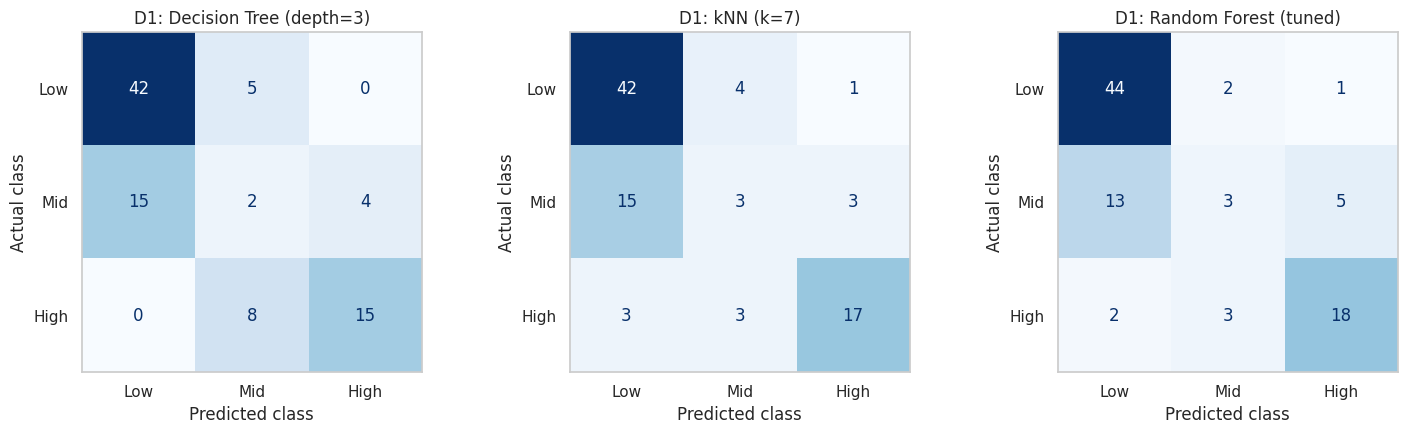

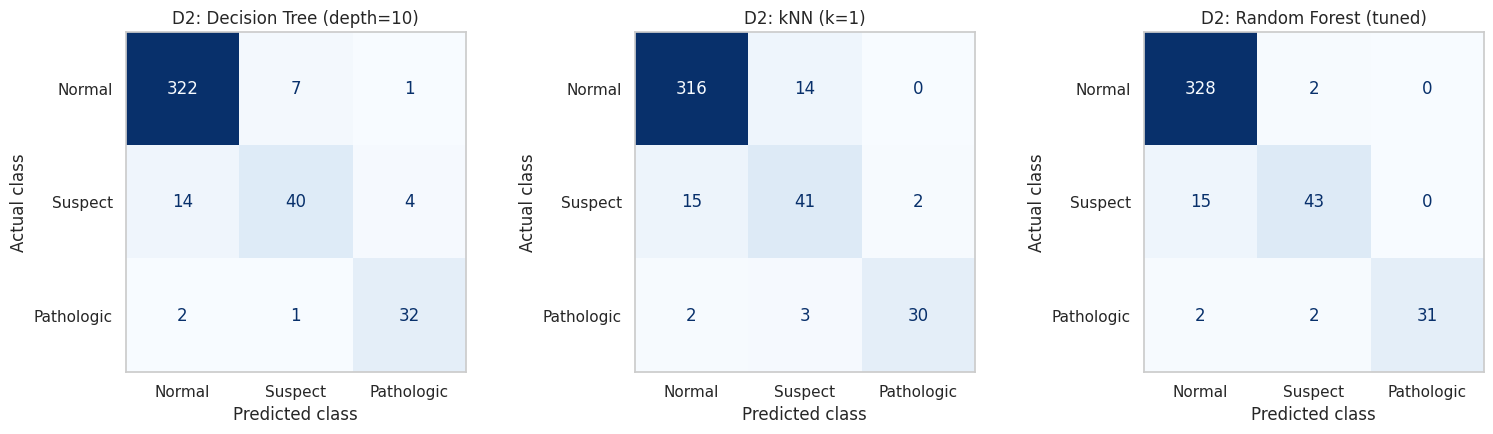

In [104]:
# [CELL 24] Confusion matrices (rows = actual class, columns = predicted class) for three models per dataset
for dataset in ['D1', 'D2']:
    S = SPLITS[dataset]
    best = BEST_PARAMS[dataset]
    models_to_plot = {f'Decision Tree (depth={best["depth"]})': FITTED[dataset][f'Decision Tree (depth={best["depth"]})'],
                      f'kNN (k={best["k"]})': FITTED[dataset][f'kNN (k={best["k"]})'],
                      'Random Forest (tuned)': TUNED[dataset]['Random Forest']}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, (model_name, model) in zip(axes, models_to_plot.items()):
        ConfusionMatrixDisplay.from_predictions(S['y_test'], model.predict(S['X_test']), display_labels=S['classes'],
                                                cmap='Blues', ax=ax, colorbar=False)
        ax.set_title(f'{dataset}: {model_name}'); ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class'); ax.grid(False)
    savefig(f'fig_{dataset}_confusion_matrices.png'); plt.show()

**Critical-class safety (D2).** On the held-out test set, Random Forest classified
31 of ~35 Pathologic cases correctly and called none of them Normal (kNN also
zero, Decision Tree one). The few non-Pathologic predictions fell into Suspect,
which still flags the case for review. For a triage support tool this is the
desired behaviour: it almost never gives false reassurance on the critical class,
and when uncertain it errs toward caution rather than missing a case.

### Handling class imbalance

Compare three strategies on Random Forest: no handling, class weighting, and
SMOTE applied inside each CV fold (so no synthetic data leaks into validation).
We track critical-class recall, since the goal is catching the minority class
(High risk / Pathologic) without losing too much overall macro-F1.

In [105]:
# [CELL 25] Class imbalance: no handling vs class weights vs SMOTE (SMOTE runs inside each CV fold, never on validation data)
imbalance_rows = []
for dataset in ['D1', 'D2']:
    S = SPLITS[dataset]
    strategies = {
        'No handling': make_pipeline(StandardScaler(), RandomForestClassifier(300, random_state=SEED)),
        'class_weight balanced': make_pipeline(StandardScaler(), RandomForestClassifier(300, class_weight='balanced', random_state=SEED)),
        'SMOTE (in-fold)': ImbPipeline([('scale', StandardScaler()), ('smote', SMOTE(random_state=SEED)),
                                        ('forest', RandomForestClassifier(300, random_state=SEED))])}
    for strategy, pipeline in strategies.items():
        cv_pred = cross_val_predict(pipeline, S['X_train'], S['y_train'], cv=CV)          # out-of-fold predictions
        pipeline.fit(S['X_train'], S['y_train'])
        test_pred = pipeline.predict(S['X_test'])
        imbalance_rows.append({'Dataset': dataset, 'Strategy': strategy,
                               'CV macro-F1': f1_score(S['y_train'], cv_pred, average='macro'),
                               'CV critical recall': recall_score(S['y_train'], cv_pred, labels=[CRITICAL_CLASS], average=None)[0],
                               'Test macro-F1': f1_score(S['y_test'], test_pred, average='macro'),
                               'Test critical recall': recall_score(S['y_test'], test_pred, labels=[CRITICAL_CLASS], average=None)[0]})
print(pd.DataFrame(imbalance_rows).round(3).to_string(index=False))

Dataset              Strategy  CV macro-F1  CV critical recall  Test macro-F1  Test critical recall
     D1           No handling        0.614               0.742          0.557                 0.739
     D1 class_weight balanced        0.608               0.730          0.557                 0.739
     D1       SMOTE (in-fold)        0.598               0.742          0.546                 0.739
     D2           No handling        0.884               0.871          0.903                 0.914
     D2 class_weight balanced        0.885               0.871          0.909                 0.914
     D2       SMOTE (in-fold)        0.891               0.928          0.914                 0.971


**Imbalance handling.** We compared no handling, class weighting, and in-fold
SMOTE on Random Forest. The effect was dataset-dependent. On the balanced D1,
mitigation gave no gain (SMOTE slightly hurt: 0.598 vs 0.614 macro-F1). On the
imbalanced D2, SMOTE clearly helped — critical-class (Pathologic) recall rose
from 0.914 to 0.971 and macro-F1 from 0.903 to 0.914. This matches theory: SMOTE
corrects genuine minority-class imbalance, so we apply it for D2 but not D1.

### Stacking ensemble

Combine the four strongest models (tuned Random Forest and Gradient Boosting,
Naïve Bayes, SVM) with a logistic-regression meta-learner that learns how to
weight them. This tests whether blending models beats the best single one.

In [106]:
# [CELL 26] Stacking: tuned Random Forest + tuned Gradient Boosting + Naive Bayes + SVM, combined by logistic regression
for dataset in ['D1', 'D2']:
    S = SPLITS[dataset]
    best_smoothing = BEST_PARAMS[dataset]['smoothing']
    stack = StackingClassifier(
        estimators=[('rf', TUNED[dataset]['Random Forest']),
                    ('gb', TUNED[dataset]['Gradient Boosting']),
                    ('nb', make_pipeline(StandardScaler(), GaussianNB(var_smoothing=best_smoothing))),
                    ('svm', make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)))],
        final_estimator=LogisticRegression(max_iter=2000, random_state=SEED), cv=CV, n_jobs=-1)
    fit_and_record(dataset, 'Stacking (RF+GB+NB+SVM)', 'Ensemble', stack)
    FITTED[dataset]['stack'] = stack

setup — TensorFlow / Keras for the neural networks

In [107]:
# R4 setup — TensorFlow / Keras for the neural networks
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 5. Neural Networks (R4)

### Tabular MLP
A small multi-layer perceptron on the two tabular datasets, to compare a neural
network against the classical models on the same data. Two hidden layers with
batch normalisation and dropout, trained with early stopping and class weights.
We expect it to roughly match, not beat, the tuned ensembles — a known result
for small tabular data.

In [108]:
# [CELL 28] MLP helpers
def build_mlp(n_features, n_classes, units, dropout, learning_rate):
    model = models.Sequential([
        layers.Input((n_features,)),
        layers.Dense(units, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout),
        layers.Dense(units // 2, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(n_classes, activation='softmax')])               # softmax gives one probability per class
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def balanced_class_weights(y):
    # rare classes get a larger weight so the loss is not dominated by the majority class
    y = np.asarray(y).astype(int)
    weights = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return {int(c): float(w) for c, w in zip(np.unique(y), weights)}

early_stop = lambda patience: callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)

### MLP hyperparameter search

Grid search over hidden units, dropout and learning rate, scored by macro-F1 on
a validation split taken from the training data. Scaling is fit on the training
portion only. The heatmaps show which configurations generalise best.

D1: best MLP configuration {'units': 32, 'dropout': 0.3, 'learning_rate': 0.01} (validation macro-F1 = 0.681)
D2: best MLP configuration {'units': 128, 'dropout': 0.0, 'learning_rate': 0.001} (validation macro-F1 = 0.870)


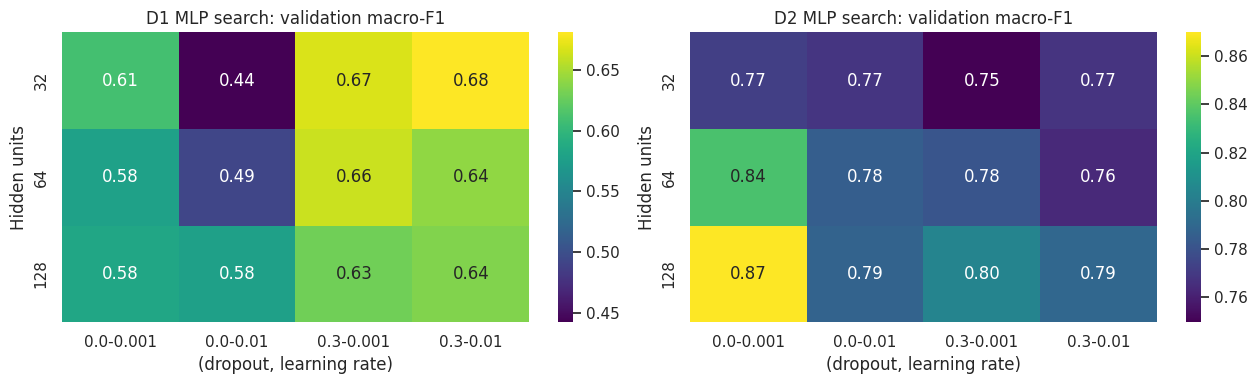

In [109]:
# [CELL 29] MLP hyper-parameter search: units x dropout x learning rate, scored on a validation split taken from the training data
search_rows, MLP_BEST = [], {}
for dataset in ['D1', 'D2']:
    S = SPLITS[dataset]
    X_fit, X_val, y_fit, y_val = train_test_split(S['X_train'], S['y_train'], test_size=0.2, stratify=S['y_train'], random_state=SEED)
    scaler = StandardScaler().fit(X_fit)                                   # fitted on the fitting part only
    X_fit_scaled, X_val_scaled = scaler.transform(X_fit), scaler.transform(X_val)
    best_score, best_config = -1, None
    for units, dropout, lr in itertools.product([32, 64, 128], [0.0, 0.3], [1e-2, 1e-3]):
        model = build_mlp(X_fit_scaled.shape[1], 3, units, dropout, lr)
        model.fit(X_fit_scaled, y_fit.values.astype(int), validation_data=(X_val_scaled, y_val.values.astype(int)), epochs=150,
                  batch_size=32, class_weight=balanced_class_weights(y_fit), verbose=0, callbacks=[early_stop(12)])
        val_f1 = f1_score(y_val, model.predict(X_val_scaled, verbose=0).argmax(axis=1), average='macro')
        search_rows.append({'Dataset': dataset, 'units': units, 'dropout': dropout, 'lr': lr, 'val macro-F1': val_f1})
        if val_f1 > best_score:
            best_score, best_config = val_f1, {'units': units, 'dropout': dropout, 'learning_rate': lr}
    MLP_BEST[dataset] = best_config
    print(f'{dataset}: best MLP configuration {best_config} (validation macro-F1 = {best_score:.3f})')

mlp_search = pd.DataFrame(search_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, dataset in zip(axes, ['D1', 'D2']):
    grid = mlp_search[mlp_search['Dataset'] == dataset].pivot_table(index='units', columns=['dropout', 'lr'], values='val macro-F1')
    sns.heatmap(grid, annot=True, fmt='.2f', cmap='viridis', ax=ax)
    ax.set_title(f'{dataset} MLP search: validation macro-F1'); ax.set_xlabel('(dropout, learning rate)'); ax.set_ylabel('Hidden units')
savefig('fig_mlp_search.png'); plt.show()

### Final MLP and training curves

Train the best MLP per dataset with early stopping, then evaluate once on the
test set. The loss and accuracy curves show convergence and whether the network
overfits. We compare the MLP's test macro-F1 against the classical models next.

D1: 57 epochs run (max 200, early stopping patience 15), batch size 32, Adam, {'units': 32, 'dropout': 0.3, 'learning_rate': 0.01}
D2: 26 epochs run (max 200, early stopping patience 15), batch size 32, Adam, {'units': 128, 'dropout': 0.0, 'learning_rate': 0.001}


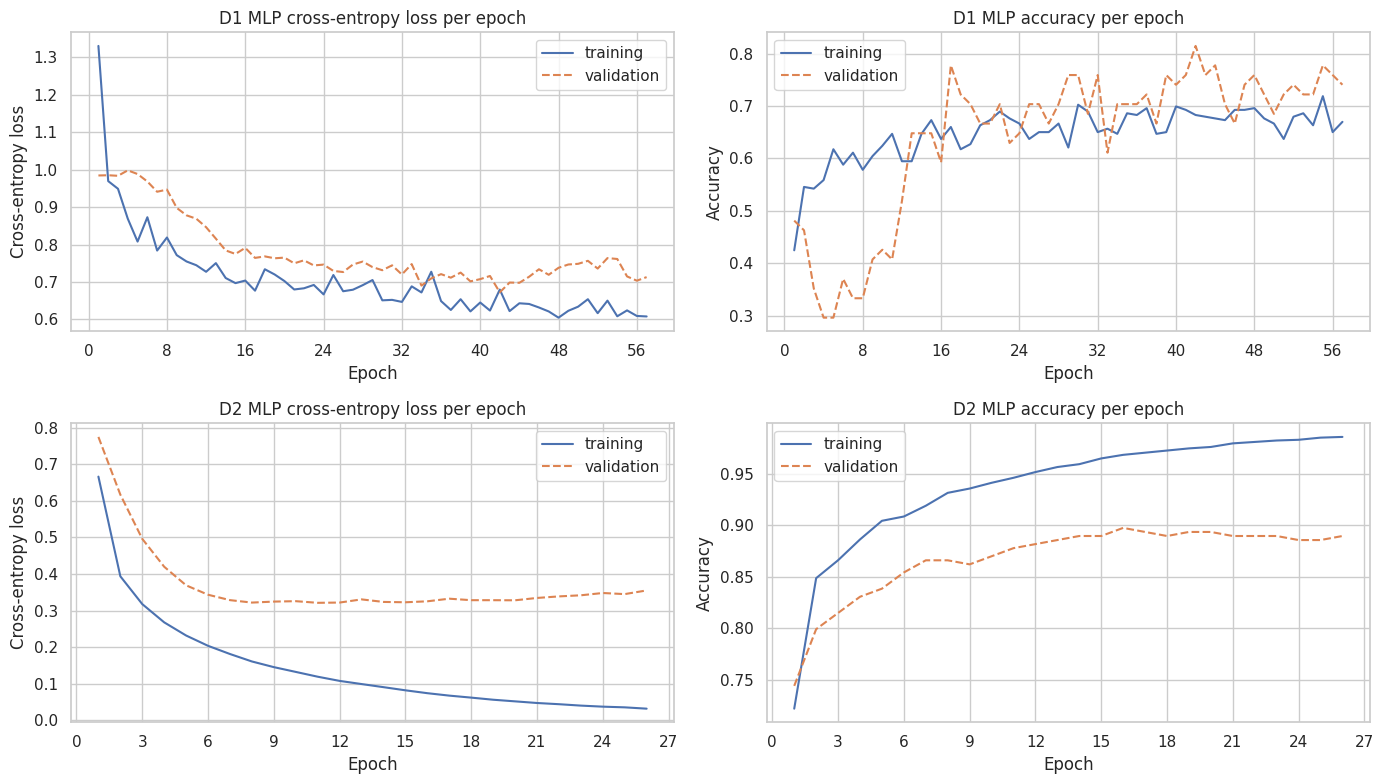

In [110]:
# [CELL 30] Final MLP for each dataset: train on the training split (15% of it held out for early stopping), evaluate once on the test split
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, dataset in enumerate(['D1', 'D2']):
    S = SPLITS[dataset]
    config = MLP_BEST[dataset]
    # explicit stratified split for early stopping; the scaler is fitted on the fitting part only
    X_fit, X_val, y_fit, y_val = train_test_split(S['X_train'], S['y_train'], test_size=0.15, stratify=S['y_train'], random_state=SEED)
    scaler = StandardScaler().fit(X_fit)
    X_fit_scaled, X_val_scaled, X_test_scaled = scaler.transform(X_fit), scaler.transform(X_val), scaler.transform(S['X_test'])

    model = build_mlp(X_fit_scaled.shape[1], 3, **config)
    history = model.fit(X_fit_scaled, y_fit.values.astype(int), validation_data=(X_val_scaled, y_val.values.astype(int)),
                        epochs=200, batch_size=32, class_weight=balanced_class_weights(y_fit), verbose=0,
                        callbacks=[early_stop(15)]).history
    epochs = np.arange(1, len(history['loss']) + 1)                       # epochs numbered from 1
    print(f'{dataset}: {len(epochs)} epochs run (max 200, early stopping patience 15), batch size 32, Adam, {config}')

    probabilities = model.predict(X_test_scaled, verbose=0)
    record(dataset, f'MLP ({config["units"]}-{config["units"] // 2}, dropout={config["dropout"]}, lr={config["learning_rate"]})',
           S['y_test'], probabilities.argmax(axis=1), probabilities, family='Neural net')

    for col, (metric, label) in enumerate([('loss', 'Cross-entropy loss'), ('accuracy', 'Accuracy')]):
        axes[row, col].plot(epochs, history[metric], label='training')
        axes[row, col].plot(epochs, history['val_' + metric], '--', label='validation')
        axes[row, col].set_title(f'{dataset} MLP {label.lower()} per epoch'); axes[row, col].set_xlabel('Epoch')
        axes[row, col].set_ylabel(label); axes[row, col].legend()
        axes[row, col].xaxis.set_major_locator(MaxNLocator(integer=True))
savefig('fig_mlp_training_curves.png'); plt.show()

In [111]:
pd.DataFrame(RESULTS).query("Dataset=='D2'")[['Model','Family','Test macro-F1','Critical-class recall']]\
  .sort_values('Test macro-F1', ascending=False).round(3).to_string(index=False)

'                              Model     Family  Test macro-F1  Critical-class recall\n              Random Forest (tuned)   Ensemble          0.910                  0.886\n          Gradient Boosting (tuned)   Ensemble          0.910                  0.943\n                  Gradient Boosting   Ensemble          0.909                  0.886\n            Stacking (RF+GB+NB+SVM)   Ensemble          0.906                  0.914\n                      Random Forest   Ensemble          0.899                  0.886\n                        Extra Trees   Ensemble          0.872                  0.829\n           Decision Tree (depth=10)  Classical          0.869                  0.914\n                          kNN (k=1)  Classical          0.852                  0.857\n                      Decision Tree  Classical          0.832                  0.914\nMLP (128-64, dropout=0.0, lr=0.001) Neural net          0.828                  0.743\n                          SVM (RBF)     Kernel       

**MLP vs classical models.** The MLP did not beat the ensembles overall. On the
large, well-separated D2 the tree ensembles clearly led (RF/GB 0.910 vs MLP
0.862). On the small, noisy D1 the MLP edged ahead (0.637 vs 0.608), but on only
91 test samples this is within noise and is partly due to the MLP's class
weighting. This confirms the known result that gradient boosting is hard to beat
on tabular data, and that neural networks offer no advantage here except
marginally on the smallest dataset.